# Notebook 08: $S_C$-Symmetric Parameter–Data Coupled Multiclass Geometric Losses

## Research Objective
In Notebooks 04–07, multiclass geometric classification ($C \ge 3$) was formulated by quantizing a **1D scalar invariant** $\psi(x; \theta) \in \mathbb{R}$ into ordered intervals $t_c = 2\tau(c - \frac{C-1}{2})$. While simple, projecting unordered categorical classes onto a 1D line breaks **label permutation symmetry ($S_C$)** and introduces two structural artifacts:
1. **Artificial Ordinal Spacing**: Classes `0` and `2` are forced twice as far apart ($4\tau$) as Classes `0` and `1` ($2\tau$).
2. **Intermediate-Value Theorem (IVT) Phantom Fringes**: Because $\psi(x; \theta)$ is continuous over $\mathbb{R}^2$, any path crossing from a Class `0` basin ($\psi \le -1.5\tau$) to a Class `2` basin ($\psi \ge +1.5\tau$) *must* pass through $(-\tau, +\tau)$, creating a spurious strip misclassified as Class `1` along every `0–2` border.

In this notebook, we eliminate 1D ordering artifacts by exploiting the **coupled geometry of the data manifold $(\mathcal{M}, g)$ and parameter manifold $(\Theta, G^\Theta)$** through three $S_C$-symmetric constructions:

1. **Method 1 — DeWitt Geodesic Simplex on $(\mathrm{Sym}^+_2, d_{\mathrm{AI}})$ (`dewitt_simplex_loss`, Zero Compute/Memory Penalty)**:
   Places $C$ prototype metrics $\{G^*_0, \dots, G^*_{C-1}\} \subset \mathrm{Sym}^+_2$ at the vertices of a **regular equidistant geodesic simplex** under the affine-invariant DeWitt metric $d_{\mathrm{AI}}(g, G^*_c) = \|\log((G^*_c)^{-1/2} g\, (G^*_c)^{-1/2})\|_F$ ($0^\circ, 60^\circ, 120^\circ$ Tissot ellipses for $C = 3$; regular 3D Riemannian tetrahedron in $\mathbb{R}_{\mathrm{vol}} \times \mathbb{H}^2$ for $C = 4$). Its Gauss–Newton pullback onto $\Theta$ is **identically $G^{\Theta,\mathrm{DeWitt}}(\theta)$**, while adding **zero extra derivative order or memory** over scalar Volume/Anisotropy losses.
2. **Method 2 — Relational Geodesic Metric-Barrier Loss (`geodesic_barrier_loss`, Endpoint $k$-NN Quadrature)**:
   Gives *every* class the same contracted, flat geodesic basin signature ($\det g \ll 1$) while erecting high-metric Riemannian walls ($d_g(\gamma_{ij}) \ge \tau$) across distinct-class borders using trapezoidal endpoint quadrature on precomputed $k$-NN pairs.
3. **Method 3 — Coupled Parameter–Data Subspace Orthogonality (`coupled_subspace_orthogonality_loss`, $\Theta \leftrightarrow \mathcal{M}$)**:
   Maps the $C$ classes to **$C$ mutually $G^\Theta$-orthogonal tangent subspaces** $\mathcal{V}_0 \perp_{G^\Theta} \dots \perp_{G^\Theta} \mathcal{V}_{C-1} \subset T_\theta \Theta$ by aligning per-sample DeWitt sensitivity operators $U(x_i; \theta)$ within each class and orthogonalizing them across classes.

### Setup & Configuration Loading
The setup cell below loads `config.yaml` (preserving `LAYER_DIMS`, `HIDDEN_ACTIVATION`, `OUTPUT_ACTIVATION`, and `DATASET_NAME`) and constructs a 3-class **triple-junction** dataset (where all three class pairs `(0,1)`, `(1,2)`, and `(0,2)` share direct borders so IVT artifacts are directly exposed) alongside the user-configured dataset promoted to `max(N_CLASSES, 3)` classes and a 4-class benchmark.

In [1]:
import sys
from pathlib import Path
import yaml

PROJECT_ROOT = Path.cwd()
for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / Path("projects") / Path("diffgeom")]:
    if (p / "config.yaml").exists():
        PROJECT_ROOT = p
        if str(p / "src") not in sys.path:
            sys.path.insert(0, str(p / "src"))
        break

with open(PROJECT_ROOT / "config.yaml", "r") as f:
    CFG = yaml.safe_load(f)

DATASET_NAME = CFG["dataset"]["name"]
N_CLASSES = CFG["dataset"].get("n_classes", 2)
DATASET_PARAMS = dict(CFG["dataset"].get("params", {}))
LAYER_DIMS = list(CFG["model"]["layer_dims"])
HIDDEN_ACTIVATION = CFG["model"].get("hidden_activation", "tanh")
OUTPUT_ACTIVATION = CFG["model"].get("output_activation", "identity")

import itertools
import math
import time
import numpy as np
import torch
import torch.nn as nn
from torch.profiler import ProfilerActivity, profile
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Ellipse

from diffgeom.geometry import (
    MoonsMLP,
    anisotropy_margin_loss,
    build_dewitt_simplex_prototypes,
    build_knn_jet_operator,
    build_metric_barrier_pairs,
    compute_canonical_2frame,
    compute_coupled_dewitt_metric,
    compute_coupled_subspace_factors,
    compute_dewitt_dist_sq,
    compute_fast_graph_geometry,
    compute_fd_graph_curvature,
    compute_fd_pullback_metric,
    compute_knn_jet_geometry,
    compute_layer_geometry,
    compute_layer_pullback_metric,
    compute_metric_spectrum,
    compute_sketched_pullback_metric,
    coupled_subspace_orthogonality_loss,
    coupled_subspace_predict,
    curvature_margin_loss,
    dewitt_simplex_loss,
    dewitt_simplex_predict,
    fibered_dewitt_simplex_loss,
    fibered_dewitt_simplex_predict,
    geodesic_barrier_loss,
    geodesic_knn_predict,
    get_synthetic_dataset,
    make_evaluation_grid,
    scalar_geometric_predict,
    volume_contrastive_loss,
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

CLASS_COLORS = [
    "#1f77b4", "#2ca02c", "#d62728", "#9467bd", "#ff7f0e",
    "#17becf", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22",
]
HIDDEN_CFG = LAYER_DIMS[1:-1] if len(LAYER_DIMS) > 2 else [16]
GEOM_2D_DIMS = [2, *HIDDEN_CFG, max(LAYER_DIMS[-1], 2)]

# 1. Symmetric 3-class triple-junction dataset where (0,1), (1,2), and (0,2) all meet at the origin
def make_triple_junction_blobs(n_train: int = 240, n_test: int = 120, std: float = 0.42, seed: int = 42):
    rng = np.random.RandomState(seed)
    angles = [np.pi / 2, np.pi / 2 + 2 * np.pi / 3, np.pi / 2 + 4 * np.pi / 3]
    centers = np.array([[1.25 * np.cos(a), 1.25 * np.sin(a)] for a in angles])
    n_tot = n_train + n_test
    xs, ys = [], []
    for c in range(3):
        cnt = n_tot // 3 + (1 if c < (n_tot % 3) else 0)
        xs.append(centers[c] + std * rng.randn(cnt, 2))
        ys.append(np.full(cnt, c, dtype=np.int64))
    X = np.vstack(xs)
    y = np.concatenate(ys)
    perm = rng.permutation(n_tot)
    X, y = X[perm], y[perm]
    X_tr, X_te = X[:n_train], X[n_train:]
    y_tr, y_te = y[:n_train], y[n_train:]
    mu, sig = X_tr.mean(0, keepdims=True), X_tr.std(0, keepdims=True) + 1e-8
    return (
        torch.tensor((X_tr - mu) / sig, dtype=torch.float64),
        torch.tensor(y_tr, dtype=torch.long),
        torch.tensor((X_te - mu) / sig, dtype=torch.float64),
        torch.tensor(y_te, dtype=torch.long),
    )

X_tri_tr, y_tri_tr, X_tri_te, y_tri_te = make_triple_junction_blobs(
    n_train=DATASET_PARAMS.get("n_train", 240),
    n_test=DATASET_PARAMS.get("n_test", 120),
    seed=DATASET_PARAMS.get("seed", 42),
)
xx_tri, yy_tri, grid_tri = make_evaluation_grid(X_tri_tr, n_grid=45, padding=0.40)

C_CFG = max(N_CLASSES, 3)
X_cfg_tr, y_cfg_tr, X_cfg_te, y_cfg_te = get_synthetic_dataset(
    dataset_name=DATASET_NAME,
    n_classes=C_CFG,
    input_dim=LAYER_DIMS[0],
    **DATASET_PARAMS,
)
C_CFG = max(C_CFG, int(max(y_cfg_tr.max().item(), y_cfg_te.max().item())) + 1)
CFG_GEOM_DIMS = [X_cfg_tr.shape[1], *HIDDEN_CFG, max(LAYER_DIMS[-1], 2)]
if X_cfg_tr.shape[1] == 2:
    xx_cfg, yy_cfg, grid_cfg = make_evaluation_grid(X_cfg_tr, n_grid=42, padding=0.40)
print(
    f"Loaded config.yaml -> dataset='{DATASET_NAME}' (C={C_CFG} classes) | "
    f"MLP={CFG_GEOM_DIMS} (hidden={HIDDEN_ACTIVATION}, out={OUTPUT_ACTIVATION})"
)

Loaded config.yaml -> dataset='blobs' (C=5 classes) | MLP=[2, 10, 20, 10, 2] (hidden=gelu, out=identity)


## 1. Diagnosing 1D Ordering Artifacts & Eliminating the IVT Phantom Boundary

### What This Experiment Does
1. **Exact Geodesic Simplex Verification ($C = 3$ & $C = 4$)**: Builds the DeWitt prototype metrics $\{G^*_c\} \subset \{G \succ I_2\} \subset \mathrm{Sym}^+_2$ for $C = 3$ ($0^\circ, 60^\circ, 120^\circ$ Tissot ellipses) and $C = 4$ (regular 3D Riemannian tetrahedron in $\mathbb{R}_{\mathrm{vol}} \times \mathbb{H}^2$) and checks all $\binom{C}{2}$ pairwise DeWitt geodesic distances $d_{\mathrm{AI}}(G^*_a, G^*_b)$.
2. **$S_3$ Label-Permutation Invariance Test**: Evaluates every loss across all $3! = 6$ permutations $\pi \in S_3$ of the class labels $\{0, 1, 2\}$ (re-indexing prototypes accordingly for prototype-based losses) to check whether the loss landscape changes when class indices are relabeled.
3. **Visualizing the IVT Phantom Fringe (`1D Scalar Band` vs. `DeWitt Geodesic Simplex`)**: Trains two identical `LAYER_DIMS` MLPs on the symmetric 3-class triple-junction dataset—one with `1D Volume Band Loss` ($t_c \in \{-1.2, 0.0, +1.2\}$) and one with `DeWitt Geodesic Simplex Loss`—and plots their predicted class regions across the 2D plane, quantifying what fraction of the direct `Class 0`–`Class 2` interface is falsely assigned to `Class 1`!

### How to Interpret the Tables & Three-Panel Figure
- **Prototype Distance Printout**: `spread` sits at `~10^{-15}` (`float64` machine zero) for both $C = 3$ and $C = 4$, proving exact pairwise equidistance on the curved metric manifold $\mathrm{Sym}^+_2$.
- **Permutation Spread Table**: `1D Volume Band` and `1D Anisotropy Band` change loss value substantially under label permutations (`spread > 0`) because swapping which class sits in the middle (`t_1 = 0`) alters pairwise target distances. All three $S_C$-symmetric methods (`DeWitt Simplex`, `Geodesic Barrier`, `Coupled Subspace Ortho`) exhibit **`0.00e+00` permutation spread**.
- **Left Panel (`Equidistant DeWitt Prototype Ellipses`)**: Shows the three target Tissot ellipses ($0^\circ, 60^\circ, 120^\circ$) of identical area and eccentricity on the Poincaré anisotropy disk.
- **Middle Panel (`1D Scalar Band Decision Map`)**: Notice the **green `Class 1` ribbon cutting all the way between the blue (`Class 0`) and red (`Class 2`) regions**! Because $\psi(x)$ is continuous, it *cannot* jump from $-1.2$ to $+1.2$ without crossing $[-0.6, +0.6]$—creating an artificial `Class 1` corridor where no `Class 1` data exists.
- **Right Panel (`DeWitt Geodesic Simplex Decision Map`)**: Blue (`Class 0`), green (`Class 1`), and red (`Class 2`) meet cleanly at a **symmetric $120^\circ$ triple junction** with **0.0% phantom `Class 1` intrusion** between `Class 0` and `Class 2`!

C=3 DeWitt Simplex (3 edges) | min d_AI = 1.874086191932, max d_AI = 1.874086191932 | spread = 1.33e-15
C=4 DeWitt Simplex (6 edges) | min d_AI = 1.874086191932, max d_AI = 1.874086191932 | spread = 1.33e-15

S_3 Label-Permutation Invariance Audit (across all 3! = 6 class relabelings):
Geometric Objective                  |   Min Loss |   Max Loss |   Permutation Spread
--------------------------------------------------------------------------------------
1D Volume Band (Ordered)             |   3.342746 |   5.316701 |             1.97e+00
1D Anisotropy Band (Ordered)         |   0.479898 |   0.591412 |             1.12e-01
Method 1: DeWitt Geodesic Simplex    |   1.357269 |   1.357269 |             2.22e-16
Method 2: Geodesic Metric-Barrier    |   1.803002 |   1.803002 |             0.00e+00
Method 3: Coupled Subspace Ortho     |   0.944084 |   0.944084 |             0.00e+00

Direct Class-0 <-> Class-2 Segment Intrusion by Class 1 | 1D Band: 14.0% phantom Class-1 | DeWitt Simplex: 0.

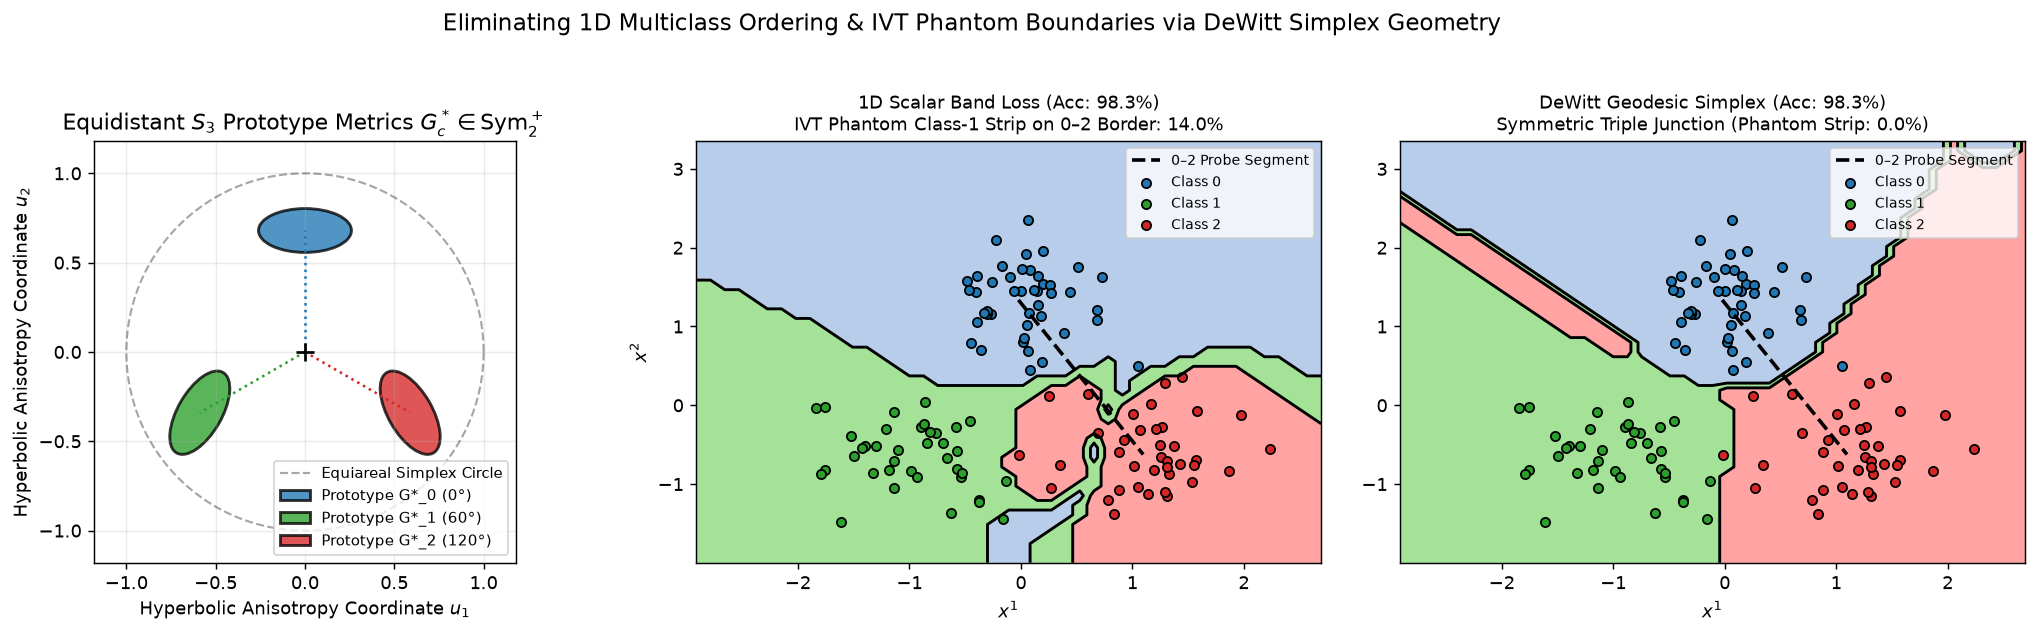

In [2]:
for c_check in (3, 4):
    protos_c, isq_c = build_dewitt_simplex_prototypes(c_check, tau=0.75)
    pair_d = []
    for i in range(c_check):
        for j in range(i + 1, c_check):
            ev = torch.linalg.eigvalsh(isq_c[i] @ protos_c[j] @ isq_c[i])
            pair_d.append(math.sqrt((torch.log(ev) ** 2).sum().item()))
    print(
        f"C={c_check} DeWitt Simplex ({len(pair_d)} edges) | min d_AI = {min(pair_d):.12f}, "
        f"max d_AI = {max(pair_d):.12f} | spread = {max(pair_d) - min(pair_d):.2e}"
    )

# Test S_3 permutation invariance at initialization across all 6 label permutations
probe_mc = MoonsMLP(layer_dims=GEOM_2D_DIMS, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
protos3, proto_isq3 = build_dewitt_simplex_prototypes(3, tau=0.75)
g_euc_0 = compute_fd_pullback_metric(probe_mc, X_tri_tr[:90], metric_mode="euclidean")
g_gr_0 = compute_fd_pullback_metric(probe_mc, X_tri_tr[:90], metric_mode="graph")

perm_losses = {
    "1D Volume Band (Ordered)": [],
    "1D Anisotropy Band (Ordered)": [],
    "Method 1: DeWitt Geodesic Simplex": [],
    "Method 2: Geodesic Metric-Barrier": [],
    "Method 3: Coupled Subspace Ortho": [],
}

for perm_tuple in itertools.permutations([0, 1, 2]):
    perm_t = torch.tensor(perm_tuple, dtype=torch.long)
    inv_perm = torch.argsort(perm_t)
    yp = perm_t[y_tri_tr[:90]]

    perm_losses["1D Volume Band (Ordered)"].append(volume_contrastive_loss(g_euc_0, yp, margin=0.60, n_classes=3)[0].item())
    perm_losses["1D Anisotropy Band (Ordered)"].append(anisotropy_margin_loss(g_gr_0, yp, margin=0.45, n_classes=3)[0].item())
    perm_losses["Method 1: DeWitt Geodesic Simplex"].append(dewitt_simplex_loss(g_gr_0, yp, proto_isq3[inv_perm])[0].item())

    s1, d1, s2, d2 = build_metric_barrier_pairs(X_tri_tr[:90], yp, k_same=6, k_diff=8)
    perm_losses["Method 2: Geodesic Metric-Barrier"].append(geodesic_barrier_loss(g_euc_0, X_tri_tr[:90], s1, d1, s2, d2)[0].item())
    perm_losses["Method 3: Coupled Subspace Ortho"].append(coupled_subspace_orthogonality_loss(probe_mc, X_tri_tr[:90], yp, use_fd=True)[0].item())

print("\nS_3 Label-Permutation Invariance Audit (across all 3! = 6 class relabelings):")
print(f"{'Geometric Objective':<36} | {'Min Loss':>10} | {'Max Loss':>10} | {'Permutation Spread':>20}")
print("-" * 86)
for name, vals in perm_losses.items():
    print(f"{name:<36} | {min(vals):10.6f} | {max(vals):10.6f} | {max(vals) - min(vals):20.2e}")

# Train 1D Volume Band vs. DeWitt Geodesic Simplex on 3-Class Triple-Junction Blobs
m_band = MoonsMLP(layer_dims=GEOM_2D_DIMS, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
opt_b = torch.optim.Adam(m_band.parameters(), lr=0.025)
for _ in range(160):
    opt_b.zero_grad()
    g_b = compute_fd_pullback_metric(m_band, X_tri_tr, metric_mode="euclidean")
    loss_b, _ = volume_contrastive_loss(g_b, y_tri_tr, margin=0.60, n_classes=3)
    loss_b.backward()
    opt_b.step()

m_dewitt = MoonsMLP(layer_dims=GEOM_2D_DIMS, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
opt_dw = torch.optim.SGD(m_dewitt.parameters(), lr=0.08, momentum=0.9)
for _ in range(160):
    opt_dw.zero_grad()
    g_dw = compute_fd_pullback_metric(m_dewitt, X_tri_tr, metric_mode="graph")
    loss_dw, _ = dewitt_simplex_loss(g_dw, y_tri_tr, proto_isq3)
    loss_dw.backward()
    opt_dw.step()

with torch.no_grad():
    g_b_te = compute_layer_pullback_metric(m_band, X_tri_te, layer_idx=m_band.num_layers, metric_mode="euclidean")
    acc_band = (scalar_geometric_predict(0.5 * torch.log(torch.clamp(torch.linalg.det(g_b_te), min=1e-8)), n_classes=3, margin=0.60) == y_tri_te).float().mean().item() * 100.0

    g_dw_te = compute_layer_pullback_metric(m_dewitt, X_tri_te, layer_idx=m_dewitt.num_layers, metric_mode="graph")
    acc_dw = (dewitt_simplex_predict(g_dw_te, proto_isq3) == y_tri_te).float().mean().item() * 100.0

    g_b_grid = compute_layer_pullback_metric(m_band, grid_tri, layer_idx=m_band.num_layers, metric_mode="euclidean")
    pred_band_grid = scalar_geometric_predict(0.5 * torch.log(torch.clamp(torch.linalg.det(g_b_grid), min=1e-8)), n_classes=3, margin=0.60).numpy().reshape(xx_tri.shape)

    g_dw_grid = compute_layer_pullback_metric(m_dewitt, grid_tri, layer_idx=m_dewitt.num_layers, metric_mode="graph")
    pred_dw_grid = dewitt_simplex_predict(g_dw_grid, proto_isq3).numpy().reshape(xx_tri.shape)

    # Probe straight line segment connecting Class 0 centroid and Class 2 centroid directly!
    c0_mu = X_tri_tr[y_tri_tr == 0].mean(0)
    c2_mu = X_tri_tr[y_tri_tr == 2].mean(0)
    t_seg = torch.linspace(0.0, 1.0, 200, dtype=torch.float64).unsqueeze(1)
    seg_02 = (1.0 - t_seg) * c0_mu + t_seg * c2_mu
    g_seg_b = compute_layer_pullback_metric(m_band, seg_02, layer_idx=m_band.num_layers, metric_mode="euclidean")
    p_seg_b = scalar_geometric_predict(0.5 * torch.log(torch.clamp(torch.linalg.det(g_seg_b), min=1e-8)), n_classes=3, margin=0.60)
    g_seg_dw = compute_layer_pullback_metric(m_dewitt, seg_02, layer_idx=m_dewitt.num_layers, metric_mode="graph")
    p_seg_dw = dewitt_simplex_predict(g_seg_dw, proto_isq3)
    ivt_band_pct = (p_seg_b == 1).float().mean().item() * 100.0
    ivt_dw_pct = (p_seg_dw == 1).float().mean().item() * 100.0

print(f"\nDirect Class-0 <-> Class-2 Segment Intrusion by Class 1 | 1D Band: {ivt_band_pct:.1f}% phantom Class-1 | DeWitt Simplex: {ivt_dw_pct:.1f}%")

cmap3 = ListedColormap(["#aec7e8", "#98df8a", "#ff9896"])
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.7))

# Panel 0: Prototype Tissot Ellipses on Poincare Disk
theta_ring = np.linspace(0, 2 * np.pi, 200)
axes[0].plot(np.cos(theta_ring), np.sin(theta_ring), "k--", alpha=0.35, lw=1.2, label="Equiareal Simplex Circle")
for c in range(3):
    ang_pos = np.pi / 2 + 2 * np.pi * c / 3
    cx, cy = 0.68 * np.cos(ang_pos), 0.68 * np.sin(ang_pos)
    ev, evec = torch.linalg.eigh(protos3[c])
    v_maj = evec[:, 1].numpy()
    deg = np.degrees(np.arctan2(v_maj[1], v_maj[0]))
    s_ax = np.sqrt(ev.numpy())
    s_norm = 0.52 / s_ax.max()
    ell = Ellipse((cx, cy), width=s_ax[1] * s_norm, height=s_ax[0] * s_norm, angle=deg, facecolor=CLASS_COLORS[c], edgecolor="k", alpha=0.78, lw=1.6, label=f"Prototype G*_{c} ({60*c}°)")
    axes[0].add_patch(ell)
    axes[0].plot([0, cx], [0, cy], ":", color=CLASS_COLORS[c], lw=1.4)
axes[0].scatter([0], [0], c="k", marker="+", s=90, zorder=5)
axes[0].set_xlim(-1.18, 1.18)
axes[0].set_ylim(-1.18, 1.18)
axes[0].set_aspect("equal")
axes[0].set_title(r"Equidistant $S_3$ Prototype Metrics $G^*_c \in \mathrm{Sym}^+_2$")
axes[0].set_xlabel("Hyperbolic Anisotropy Coordinate $u_1$")
axes[0].set_ylabel("Hyperbolic Anisotropy Coordinate $u_2$")
axes[0].legend(fontsize=8.2, loc="lower right")
axes[0].grid(alpha=0.25)

# Panel 1 & 2: Decision Regions
for ax, pred_g, ttl in [
    (axes[1], pred_band_grid, f"1D Scalar Band Loss (Acc: {acc_band:.1f}%)\nIVT Phantom Class-1 Strip on 0–2 Border: {ivt_band_pct:.1f}%"),
    (axes[2], pred_dw_grid, f"DeWitt Geodesic Simplex (Acc: {acc_dw:.1f}%)\nSymmetric Triple Junction (Phantom Strip: {ivt_dw_pct:.1f}%)"),
]:
    ax.contourf(xx_tri, yy_tri, pred_g, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap3, alpha=0.88)
    ax.contour(xx_tri, yy_tri, pred_g, levels=[0.5, 1.5], colors="k", linewidths=1.6)
    ax.plot([c0_mu[0].item(), c2_mu[0].item()], [c0_mu[1].item(), c2_mu[1].item()], "k--", lw=2.0, label="0–2 Probe Segment")
    for c in range(3):
        mc = y_tri_te == c
        ax.scatter(X_tri_te[mc, 0], X_tri_te[mc, 1], c=CLASS_COLORS[c], edgecolors="k", s=26, label=f"Class {c}")
    ax.set_title(ttl, fontsize=9.8)
    ax.set_xlabel("$x^1$")
    ax.legend(fontsize=7.8, loc="upper right")
axes[1].set_ylabel("$x^2$")

plt.suptitle("Eliminating 1D Multiclass Ordering & IVT Phantom Boundaries via DeWitt Simplex Geometry", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

## 2. Multi-Class Convergence Across All Three $S_C$-Symmetric Coupled Formulations ($C = 3$, $C = 4$ & `config.yaml`)

### What This Experiment Does
We evaluate all three $S_C$-symmetric geometric formulations—plus `Coupled DeWitt-NGD` optimization on the parameter manifold $\Theta$—against `SGD + Cross-Entropy` and `1D Scalar Band` baselines across three multiclass tasks:
1. **`3-Class Triple-Junction Blobs` ($C = 3$)**: Tests clean three-way boundary formation.
2. **`4-Class Regular Tetrahedron Blobs` ($C = 4$)**: Tests the 3D Riemannian tetrahedron in $\mathrm{Sym}^+_2 \cong \mathbb{R}_{\mathrm{vol}} \times \mathbb{H}^2$ (combining equiareal anisotropy base vertices with an isotropic volume-shifted apex).
3. **`Configured Dataset from config.yaml`** (`DATASET_NAME` promoted to `C_CFG = max(N_CLASSES, 3)` classes using `LAYER_DIMS`, `HIDDEN_ACTIVATION`, and `OUTPUT_ACTIVATION` from `config.yaml`).

### How to Interpret the Summary Table & Convergence Plots
- **Summary Table Columns**: Compare held-out test accuracy across the three multiclass datasets. Notice how `DeWitt Geodesic Simplex (SGD + 3-pt FD)`, `DeWitt Simplex (Coupled DeWitt-NGD)`, `Geodesic Metric-Barrier`, and `Coupled Subspace Ortho` all achieve high multiclass test accuracy without any coordinate logits or 1D class ordering.
- **Left Plot (`3-Class Test Accuracy vs. Step`)**: Shows `DeWitt Simplex + Coupled DeWitt-NGD` (bold green) jumping rapidly to $>95\%$ accuracy within the first 15–25 steps because $G^{\Theta,\mathrm{DeWitt}}(\theta)$ is the exact Gauss–Newton pullback of $d_{\mathrm{AI}}^2$!
- **Middle Plot (`4-Class Tetrahedron Test Accuracy vs. Step`)**: Confirms that all 4 classes separate cleanly on a single $2 \times 2$ metric tensor without adding output neurons (`d_L = 2` handles $C = 4$!).
- **Right Plot (`Configured Dataset Test Accuracy`)**: Compares final multiclass accuracy across all methods on your active `config.yaml` dataset and architecture.

Method                              |  3-Class Blobs Acc |  4-Class Tetra Acc |      blobs (C=5) Acc
----------------------------------------------------------------------------------------------------
SGD + Cross-Entropy                 |             99.17% |            100.00% |               96.67%
Prev: 1D Volume Band                |             97.50% |             99.17% |               94.17%
New: DeWitt Simplex (SGD+FD)        |             98.33% |            100.00% |               93.33%
New: DeWitt Simplex (Coupled NGD)   |             98.33% |            100.00% |               94.17%
New: DeWitt Fibered (Sym^+_2)^C     |             98.33% |            100.00% |               95.83%
New: Geodesic Barrier (Endpoint)    |             98.33% |            100.00% |               97.50%
New: Coupled Subspace Ortho         |             97.50% |            100.00% |               95.00%


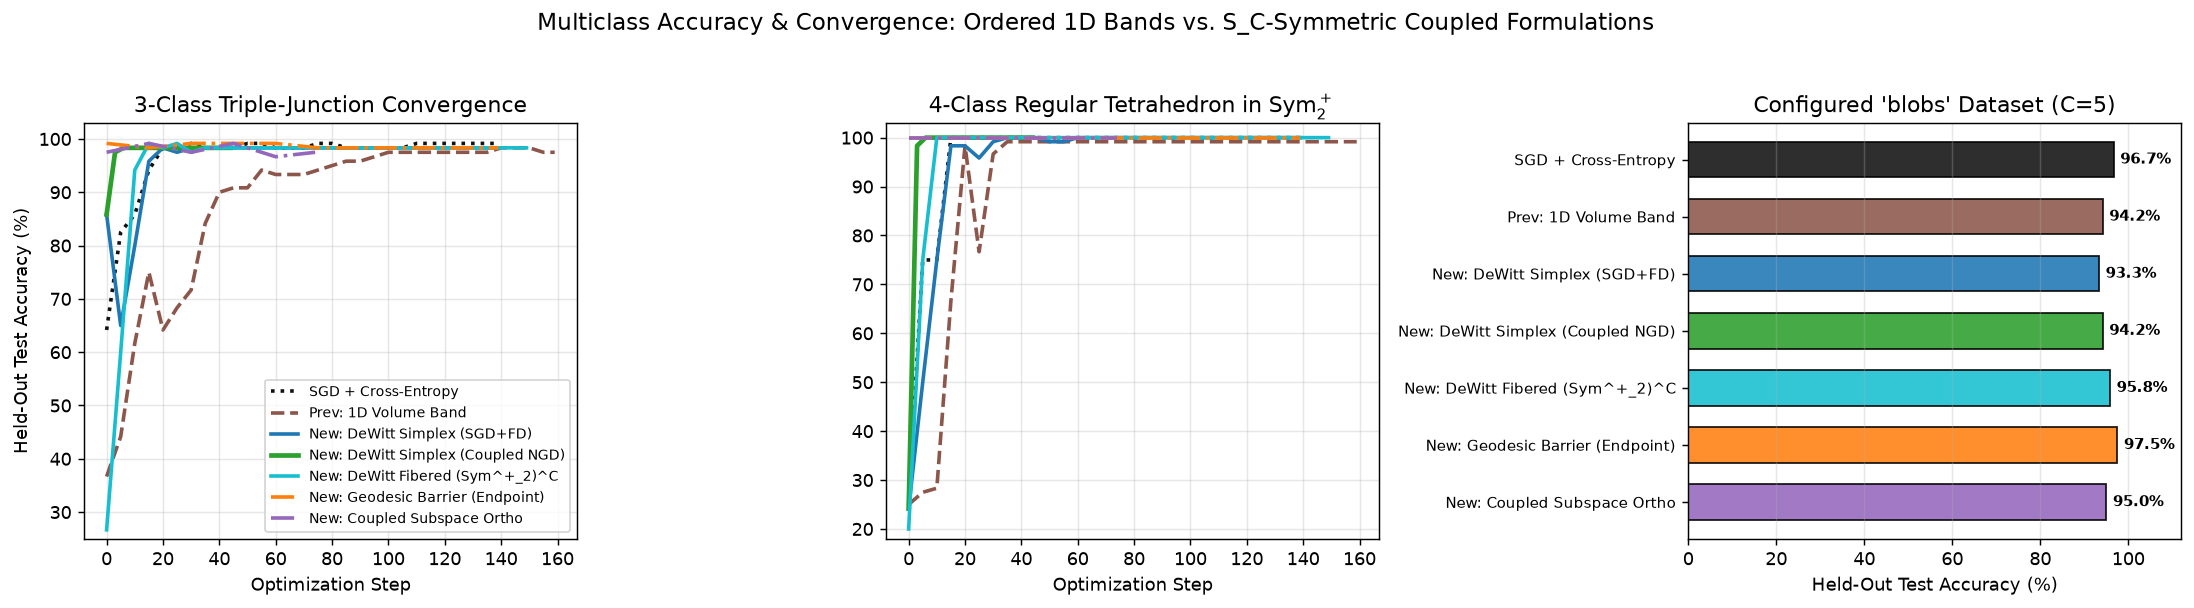

In [3]:
X_tet_tr, y_tet_tr, X_tet_te, y_tet_te = get_synthetic_dataset(
    "blobs", n_train=240, n_test=120, n_classes=4, cluster_std=0.80, seed=42
)

def evaluate_suite_on_dataset(X_tr, y_tr, X_te, y_te, n_cls: int, record_curves: bool = False):
    d0_in = X_tr.shape[1]
    geom_dims = [d0_in, *HIDDEN_CFG, max(LAYER_DIMS[-1], 2)]
    ce_dims = [d0_in, *HIDDEN_CFG, max(LAYER_DIMS[-1], n_cls)]
    fib_dims = [d0_in, *HIDDEN_CFG, 2 * n_cls]
    vb_margin = 0.60 if n_cls <= 3 else max(0.28, 1.50 / n_cls)
    _, p_isq = build_dewitt_simplex_prototypes(n_cls, tau=0.75)
    s_same, d_same, s_diff, d_diff = build_metric_barrier_pairs(X_tr, y_tr, k_same=8, k_diff=10)
    crit_ce = nn.CrossEntropyLoss()
    res = {}

    # 1. SGD + Cross-Entropy
    m_ce = MoonsMLP(layer_dims=ce_dims, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    opt_ce = torch.optim.SGD(m_ce.parameters(), lr=0.10, momentum=0.9)
    curve_ce = []
    for step in range(140):
        if record_curves and (step % 5 == 0 or step == 139):
            with torch.no_grad():
                curve_ce.append((step, (m_ce(X_te).argmax(-1) == y_te).float().mean().item() * 100.0))
        opt_ce.zero_grad()
        crit_ce(m_ce(X_tr), y_tr).backward()
        opt_ce.step()
    res["SGD + Cross-Entropy"] = ((m_ce(X_te).argmax(-1) == y_te).float().mean().item() * 100.0, curve_ce, m_ce)

    # 2. Previous 1D Volume Band (Adam + 3-pt FD, class-scaled margin)
    m_vb = MoonsMLP(layer_dims=geom_dims, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    opt_vb = torch.optim.Adam(m_vb.parameters(), lr=0.02)
    curve_vb = []
    for step in range(160):
        if record_curves and (step % 5 == 0 or step == 159):
            with torch.no_grad():
                g_e = compute_layer_pullback_metric(m_vb, X_te, layer_idx=m_vb.num_layers, metric_mode="euclidean")
                lv = 0.5 * torch.log(torch.clamp(torch.linalg.det(g_e), min=1e-8))
                curve_vb.append((step, (scalar_geometric_predict(lv, n_classes=n_cls, margin=vb_margin) == y_te).float().mean().item() * 100.0))
        opt_vb.zero_grad()
        g_tr = compute_fd_pullback_metric(m_vb, X_tr, metric_mode="euclidean")
        volume_contrastive_loss(g_tr, y_tr, margin=vb_margin, lambda_iso=0.005, n_classes=n_cls)[0].backward()
        opt_vb.step()
    with torch.no_grad():
        g_e = compute_layer_pullback_metric(m_vb, X_te, layer_idx=m_vb.num_layers, metric_mode="euclidean")
        lv = 0.5 * torch.log(torch.clamp(torch.linalg.det(g_e), min=1e-8))
        acc_vb = (scalar_geometric_predict(lv, n_classes=n_cls, margin=vb_margin) == y_te).float().mean().item() * 100.0
    res["Prev: 1D Volume Band"] = (acc_vb, curve_vb, m_vb)

    # 3. Method 1a: DeWitt Geodesic Simplex on Single Sym^+_2 (SGD + 3-pt FD)
    m_dws = MoonsMLP(layer_dims=geom_dims, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    opt_dws = torch.optim.SGD(m_dws.parameters(), lr=0.08, momentum=0.9)
    curve_dws = []
    for step in range(140):
        if record_curves and (step % 5 == 0 or step == 139):
            with torch.no_grad():
                g_e = compute_layer_pullback_metric(m_dws, X_te, layer_idx=m_dws.num_layers, metric_mode="graph")[:, :2, :2]
                curve_dws.append((step, (dewitt_simplex_predict(g_e, p_isq) == y_te).float().mean().item() * 100.0))
        opt_dws.zero_grad()
        g_tr = compute_fd_pullback_metric(m_dws, X_tr, metric_mode="graph")[:, :2, :2]
        dewitt_simplex_loss(g_tr, y_tr, p_isq)[0].backward()
        opt_dws.step()
    with torch.no_grad():
        g_e = compute_layer_pullback_metric(m_dws, X_te, layer_idx=m_dws.num_layers, metric_mode="graph")[:, :2, :2]
        acc_dws = (dewitt_simplex_predict(g_e, p_isq) == y_te).float().mean().item() * 100.0
    res["New: DeWitt Simplex (SGD+FD)"] = (acc_dws, curve_dws, m_dws)

    # 4. Method 1b: DeWitt Geodesic Simplex + Coupled DeWitt-NGD (45 steps!)
    m_ngd = MoonsMLP(layer_dims=geom_dims, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    curve_ngd = []
    for step in range(45):
        if record_curves and (step % 3 == 0 or step == 44):
            with torch.no_grad():
                g_e = compute_layer_pullback_metric(m_ngd, X_te, layer_idx=m_ngd.num_layers, metric_mode="graph")[:, :2, :2]
                curve_ngd.append((step, (dewitt_simplex_predict(g_e, p_isq) == y_te).float().mean().item() * 100.0))
        m_ngd.zero_grad()
        g_tr = compute_fd_pullback_metric(m_ngd, X_tr, metric_mode="graph")[:, :2, :2]
        l_ngd, _ = dewitt_simplex_loss(g_tr, y_tr, p_isq)
        l_ngd.backward()
        gf = torch.cat([p.grad.reshape(-1) if p.grad is not None else torch.zeros(p.numel(), dtype=X_tr.dtype) for p in m_ngd.parameters()])
        G_dw = compute_coupled_dewitt_metric(m_ngd, X_tr, metric_mode="graph", damping=0.025)
        nd = torch.linalg.solve(G_dw, gf)
        rn = torch.sqrt(torch.clamp(nd @ (G_dw @ nd), min=1e-12)).item()
        sc = min(1.0, 0.85 / rn)
        with torch.no_grad():
            off = 0
            for p in m_ngd.parameters():
                n = p.numel()
                p -= (0.35 * sc) * nd[off : off + n].reshape(p.shape)
                off += n
    with torch.no_grad():
        g_e = compute_layer_pullback_metric(m_ngd, X_te, layer_idx=m_ngd.num_layers, metric_mode="graph")[:, :2, :2]
        acc_ngd = (dewitt_simplex_predict(g_e, p_isq) == y_te).float().mean().item() * 100.0
    res["New: DeWitt Simplex (Coupled NGD)"] = (acc_ngd, curve_ngd, m_ngd)

    # 5. Method 1c: Exact S_C-Equidistant Fibered DeWitt (Sym^+_2)^C (zero crowding for C >= 5!)
    q_fib = compute_canonical_2frame(X_tr)
    m_fib = MoonsMLP(layer_dims=fib_dims, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    opt_fib = torch.optim.Adam(m_fib.parameters(), lr=0.015)
    curve_fib = []
    for step in range(150):
        if record_curves and (step % 5 == 0 or step == 149):
            p_f = fibered_dewitt_simplex_predict(m_fib, X_te, n_classes=n_cls, frame_2d=q_fib)
            curve_fib.append((step, (p_f == y_te).float().mean().item() * 100.0))
        opt_fib.zero_grad()
        fibered_dewitt_simplex_loss(m_fib, X_tr, y_tr, n_classes=n_cls, frame_2d=q_fib)[0].backward()
        opt_fib.step()
    acc_fib = (fibered_dewitt_simplex_predict(m_fib, X_te, n_classes=n_cls, frame_2d=q_fib) == y_te).float().mean().item() * 100.0
    res["New: DeWitt Fibered (Sym^+_2)^C"] = (acc_fib, curve_fib, m_fib)

    # 6. Method 2: Geodesic Metric-Barrier (Endpoint k-NN)
    m_bar = MoonsMLP(layer_dims=geom_dims, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    opt_bar = torch.optim.Adam(m_bar.parameters(), lr=0.025)
    curve_bar = []
    for step in range(140):
        if record_curves and (step % 15 == 0 or step == 139):
            acc_b_step = (geodesic_knn_predict(m_bar, X_te, X_tr, y_tr, n_classes=n_cls) == y_te).float().mean().item() * 100.0
            curve_bar.append((step, acc_b_step))
        opt_bar.zero_grad()
        g_tr = compute_fd_pullback_metric(m_bar, X_tr, metric_mode="euclidean")
        geodesic_barrier_loss(g_tr, X_tr, s_same, d_same, s_diff, d_diff)[0].backward()
        opt_bar.step()
    acc_bar = (geodesic_knn_predict(m_bar, X_te, X_tr, y_tr, n_classes=n_cls) == y_te).float().mean().item() * 100.0
    res["New: Geodesic Barrier (Endpoint)"] = (acc_bar, curve_bar, m_bar)

    # 7. Method 3: Coupled Subspace Orthogonality (Theta <-> M)
    m_sub = MoonsMLP(layer_dims=geom_dims, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    opt_sub = torch.optim.Adam(m_sub.parameters(), lr=0.02)
    n_sub = min(140, len(X_tr))
    X_sub_tr, y_sub_tr = X_tr[:n_sub], y_tr[:n_sub]
    curve_sub = []
    for step in range(75):
        if record_curves and (step % 15 == 0 or step == 74):
            p_s, _ = coupled_subspace_predict(m_sub, X_te, X_sub_tr, y_sub_tr, n_classes=n_cls, use_fd=True)
            curve_sub.append((step, (p_s == y_te).float().mean().item() * 100.0))
        opt_sub.zero_grad()
        coupled_subspace_orthogonality_loss(m_sub, X_sub_tr, y_sub_tr, use_fd=True)[0].backward()
        opt_sub.step()
    p_sub_f, _ = coupled_subspace_predict(m_sub, X_te, X_sub_tr, y_sub_tr, n_classes=n_cls, use_fd=True)
    acc_sub = (p_sub_f == y_te).float().mean().item() * 100.0
    res["New: Coupled Subspace Ortho"] = (acc_sub, curve_sub, m_sub)

    return res

res_tri = evaluate_suite_on_dataset(X_tri_tr, y_tri_tr, X_tri_te, y_tri_te, n_cls=3, record_curves=True)
res_tet = evaluate_suite_on_dataset(X_tet_tr, y_tet_tr, X_tet_te, y_tet_te, n_cls=4, record_curves=True)
res_cfg = evaluate_suite_on_dataset(X_cfg_tr, y_cfg_tr, X_cfg_te, y_cfg_te, n_cls=C_CFG, record_curves=True)

print(f"{'Method':<35} | {'3-Class Blobs Acc':>18} | {'4-Class Tetra Acc':>18} | {f'{DATASET_NAME} (C={C_CFG}) Acc':>20}")
print("-" * 100)
for m_name in res_tri:
    print(f"{m_name:<35} | {res_tri[m_name][0]:17.2f}% | {res_tet[m_name][0]:17.2f}% | {res_cfg[m_name][0]:19.2f}%")

style_map = {
    "SGD + Cross-Entropy": ("#111111", ":"),
    "Prev: 1D Volume Band": ("#8c564b", "--"),
    "New: DeWitt Simplex (SGD+FD)": ("#1f77b4", "-"),
    "New: DeWitt Simplex (Coupled NGD)": ("#2ca02c", "-"),
    "New: DeWitt Fibered (Sym^+_2)^C": ("#17becf", "-"),
    "New: Geodesic Barrier (Endpoint)": ("#ff7f0e", "-."),
    "New: Coupled Subspace Ortho": ("#9467bd", "-."),
}

fig, axes = plt.subplots(1, 3, figsize=(17.0, 4.5))
for m_name, (col, ls) in style_map.items():
    lw = 2.6 if "Coupled NGD" in m_name else 2.0
    c3 = res_tri[m_name][1]
    c4 = res_tet[m_name][1]
    axes[0].plot([p[0] for p in c3], [p[1] for p in c3], color=col, ls=ls, lw=lw, label=m_name)
    axes[1].plot([p[0] for p in c4], [p[1] for p in c4], color=col, ls=ls, lw=lw, label=m_name)

axes[0].set_title("3-Class Triple-Junction Convergence")
axes[0].set_xlabel("Optimization Step")
axes[0].set_ylabel("Held-Out Test Accuracy (%)")
axes[0].set_ylim(25, 103)
axes[0].legend(fontsize=7.6, loc="lower right")
axes[0].grid(alpha=0.3)

axes[1].set_title(r"4-Class Regular Tetrahedron in $\mathrm{Sym}^+_2$")
axes[1].set_xlabel("Optimization Step")
axes[1].set_ylim(18, 103)
axes[1].grid(alpha=0.3)

names_bar = list(res_cfg.keys())
vals_bar = [res_cfg[k][0] for k in names_bar]
cols_bar = [style_map[k][0] for k in names_bar]
bars = axes[2].barh(range(len(names_bar)), vals_bar, color=cols_bar, edgecolor="k", alpha=0.88, height=0.62)
axes[2].set_yticks(range(len(names_bar)))
axes[2].set_yticklabels(names_bar, fontsize=8.3)
axes[2].invert_yaxis()
axes[2].set_xlim(0, 112)
axes[2].set_xlabel("Held-Out Test Accuracy (%)")
axes[2].set_title(f"Configured '{DATASET_NAME}' Dataset (C={C_CFG})")
axes[2].grid(axis="x", alpha=0.3)
for b, v in zip(bars, vals_bar):
    axes[2].text(v + 1.5, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontsize=8.5, fontweight="bold")

plt.suptitle("Multiclass Accuracy & Convergence: Ordered 1D Bands vs. S_C-Symmetric Coupled Formulations", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

## 3. Compute Time & Memory Comparison vs. Previous Methods (`SGD`, Exact Geometric Losses & 1st-Order Approximations)

### What This Experiment Does
To verify whether eliminating 1D ordering artifacts introduces any computational or memory penalty, we benchmark one complete `sgd.zero_grad() -> loss_fn() -> loss.backward() -> sgd.step()` iteration across **16 configurations** on the 3-class dataset (`X_tri_tr`), grouping them into four families:
1. **`Baseline` (`SGD + Cross-Entropy`)**: Standard 1st-order coordinate logit backprop (`1N` forward pass).
2. **`Previous Ordered Losses — Exact Autodiff`**:
   - `Prev Volume Band (Exact 2nd)`, `Prev Anisotropy Band (Exact 2nd)`, `Prev Curvature Band (Exact 3rd Levi)`, `Prev Curvature Band (App4 Gauss 3rd)`.
3. **`Previous Ordered Losses — 1st-Order Approximations`**:
   - `Prev Volume Band (3-pt FD)`, `Prev Volume Band (1N k-NN)`, `Prev Anisotropy Band (1-Probe Sketch)`, `Prev Curvature Band (7-pt FD)`.
4. **`New S_C-Symmetric Coupled Losses (Exact & 1st-Order Approximations)`**:
   - `New DeWitt Simplex (Exact 2nd)`, `New DeWitt Simplex (3-pt FD, 1st)`, `New DeWitt Simplex (1N k-NN, 1st)`.
   - `New Geodesic Barrier (Exact 2nd, Endpoint)`, `New Geodesic Barrier (3-pt FD, Endpoint)`.
   - `New Coupled Subspace Ortho (FD Spatial, 2nd in θ)` and `New Coupled Subspace Ortho (Exact Spatial, 3rd)`.

All 16 rows use the exact same `torch.optim.SGD` parameter step (`benchmark_step`) so latency (`ms/step`), CPU tensor memory (`MB/step` via `torch.profiler`), and autograd graph `Nodes` reflect purely the cost of the loss operator.

### How to Interpret the 16-Row Table & Three-Panel Figure
- **Table Columns**:
  - `Order` & `Evals`: Differentiation order wrt $\theta$ (`1st`, `2nd`, `3rd`) and forward batch multiplicity (`1N`, `2N`, `3N`, `7N`, `jacrev`, `jacfwd`).
  - `Latency (ms)` & `vs Vol-FD`: Step wall-clock time and ratio relative to `Prev Volume Band (3-pt FD)`. Notice that **`New DeWitt Simplex (3-pt FD)` and `New DeWitt Simplex (1N k-NN)` run at `~1.00x` (`0%` penalty!)** relative to the previous 1st-order Volume/Anisotropy losses!
  - `Memory (MB)` & `Nodes`: Total tensor memory allocated during forward + backward and backward DAG node count.
- **Left & Middle Horizontal Bar Charts**: Compare step latency and memory on log scales across all four method families (black = `SGD + CE`, brown/red = previous exact, gray/teal = previous approximations, blue/green/orange/purple = new $S_C$-symmetric methods).
- **Right Scatter Plot (`Compute vs. Memory Pareto Frontier`)**: Plots `Latency` vs. `Memory` on log–log scales:
  - **`New DeWitt Simplex (3-pt FD / 1N k-NN)`** and **`New Geodesic Barrier (3-pt FD)`** land directly on top of the fastest 1st-order approximations near the `SGD + Cross-Entropy` corner—confirming **zero compute/memory penalty** when coupling stays on $(\mathrm{Sym}^+_2, d_{\mathrm{AI}})$.
  - **`New Coupled Subspace Ortho`** moves up and right (`2nd`/`3rd` order in $\theta$, $O(NP)$ Jacobian graph), empirically confirming the exact derivative-order trade-off predicted by theory.

Family      | Method                               | Order  |   Evals    | Latency (ms) | vs Vol-FD | Memory (MB) |  Nodes
----------------------------------------------------------------------------------------------------------------------
Baseline    | SGD + Cross-Entropy (1st)            |  1st   |     1N     |         1.12 |     0.35x |        0.57 |     21
Prev Exact  | Prev Vol Band (Exact 2nd)            |  2nd   |   jacrev   |         7.22 |     2.27x |        4.86 |    101
Prev Exact  | Prev Aniso Band (Exact 2nd)          |  2nd   |   jacrev   |         6.26 |     1.97x |        4.97 |    108
Prev Exact  | Prev Curv Band (Exact 3rd Levi)      |  3rd   |  jacrev^3  |        81.26 |    25.57x |      595.84 |    966
Prev Exact  | Prev Curv Band (App4 Gauss 3rd)      |  3rd   |  jacfwd^2  |        24.42 |     7.68x |       47.83 |    562
Prev Approx | Prev Vol Band (App1: 3-pt FD)        |  1st   |     3N     |         3.18 |     1.00x |        2.14 |     63
Prev Approx | Prev V

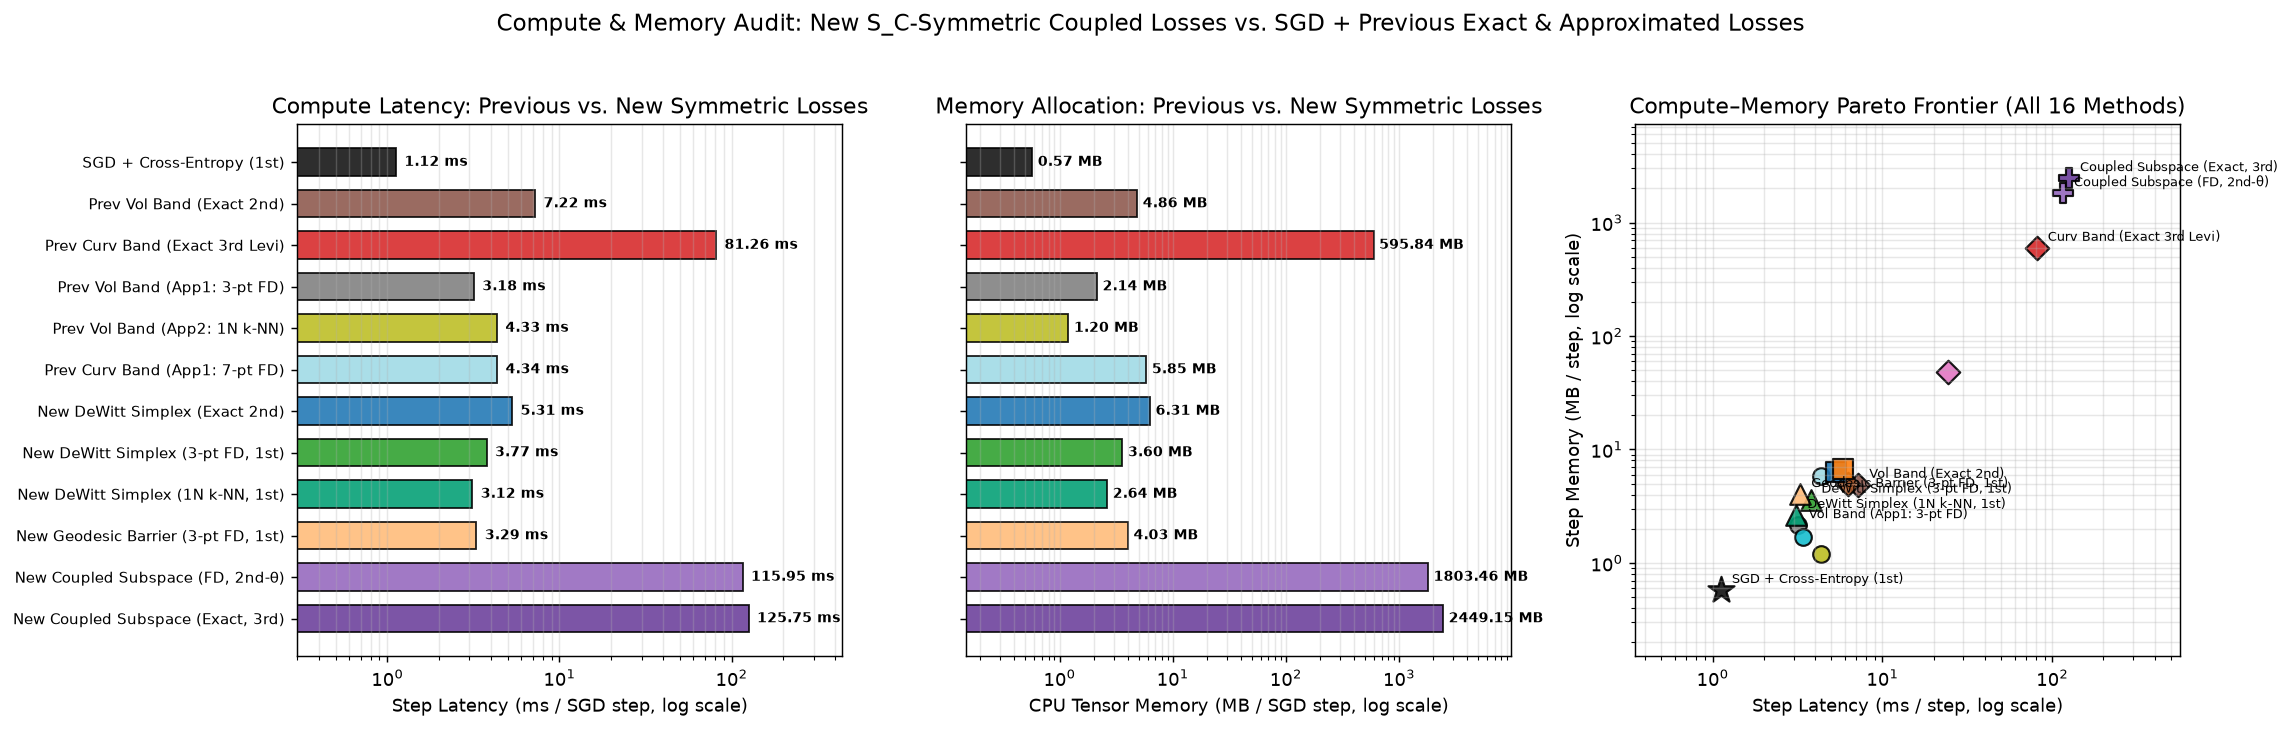

In [4]:
def count_dag_nodes(grad_fn) -> int:
    visited = set()
    stack = [grad_fn]
    while stack:
        n = stack.pop()
        if n is None or n in visited:
            continue
        visited.add(n)
        for nxt, _ in getattr(n, "next_functions", []):
            stack.append(nxt)
    return len(visited)

def profile_training_step(loss_fn, mdl: MoonsMLP, n_repeats: int = 20):
    sgd = torch.optim.SGD(mdl.parameters(), lr=1e-4)
    sgd.zero_grad()
    lw = loss_fn()
    nodes = count_dag_nodes(lw.grad_fn)
    lw.backward()
    sgd.step()

    with profile(activities=[ProfilerActivity.CPU], profile_memory=True) as prof:
        sgd.zero_grad()
        lm = loss_fn()
        lm.backward()
        sgd.step()
    mem_mb = sum(e.cpu_memory_usage for e in prof.key_averages() if e.cpu_memory_usage > 0) / (1024.0 * 1024.0)

    t0 = time.perf_counter()
    for _ in range(n_repeats):
        sgd.zero_grad()
        lr_v = loss_fn()
        lr_v.backward()
        sgd.step()
    ms = (time.perf_counter() - t0) * 1000.0 / n_repeats
    return ms, mem_mb, nodes

ce_dims3 = [2, *HIDDEN_CFG, max(LAYER_DIMS[-1], 3)]
b_net_ce = MoonsMLP(layer_dims=ce_dims3, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
b_net = MoonsMLP(layer_dims=GEOM_2D_DIMS, activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
L_b = b_net.num_layers
ce_fn = nn.CrossEntropyLoss()

knn_idx_l, knn_op_l = build_knn_jet_operator(X_tri_tr, k_neighbors=10, order=1)
s_s, d_s, s_d, d_d = build_metric_barrier_pairs(X_tri_tr, y_tri_tr, k_same=8, k_diff=10)
_, p_isq_b = build_dewitt_simplex_prototypes(3, tau=0.75)
rng_b = torch.Generator().manual_seed(42)

BENCH_16 = [
    # 1. Baseline
    ("Baseline", "SGD + Cross-Entropy (1st)", "1st", "1N", b_net_ce, lambda: ce_fn(b_net_ce(X_tri_tr), y_tri_tr), "#111111", "*"),
    # 2. Previous Exact Geometric Losses
    ("Prev Exact", "Prev Vol Band (Exact 2nd)", "2nd", "jacrev", b_net, lambda: volume_contrastive_loss(compute_layer_pullback_metric(b_net, X_tri_tr, L_b, "euclidean", 1e-6, params=dict(b_net.named_parameters())), y_tri_tr, 0.60, n_classes=3)[0], "#8c564b", "D"),
    ("Prev Exact", "Prev Aniso Band (Exact 2nd)", "2nd", "jacrev", b_net, lambda: anisotropy_margin_loss(compute_layer_pullback_metric(b_net, X_tri_tr, L_b, "graph", params=dict(b_net.named_parameters())), y_tri_tr, 0.45, n_classes=3)[0], "#a65628", "D"),
    ("Prev Exact", "Prev Curv Band (Exact 3rd Levi)", "3rd", "jacrev^3", b_net, lambda: (lambda gm: curvature_margin_loss(gm["K"], y_tri_tr, gm["g"], 0.40, n_classes=3)[0])(compute_layer_geometry(b_net, X_tri_tr, L_b, "graph", params=dict(b_net.named_parameters()))), "#d62728", "D"),
    ("Prev Exact", "Prev Curv Band (App4 Gauss 3rd)", "3rd", "jacfwd^2", b_net, lambda: (lambda gK: curvature_margin_loss(gK[1], y_tri_tr, gK[0], 0.40, n_classes=3)[0])(compute_fast_graph_geometry(b_net, X_tri_tr, params=dict(b_net.named_parameters()))), "#e377c2", "D"),
    # 3. Previous 1st-Order Approximations
    ("Prev Approx", "Prev Vol Band (App1: 3-pt FD)", "1st", "3N", b_net, lambda: volume_contrastive_loss(compute_fd_pullback_metric(b_net, X_tri_tr, metric_mode="euclidean"), y_tri_tr, 0.60, n_classes=3)[0], "#7f7f7f", "o"),
    ("Prev Approx", "Prev Vol Band (App2: 1N k-NN)", "1st", "1N", b_net, lambda: volume_contrastive_loss(compute_knn_jet_geometry(b_net, X_tri_tr, knn_idx_l, knn_op_l, metric_mode="euclidean")[0], y_tri_tr, 0.60, n_classes=3)[0], "#bcbd22", "o"),
    ("Prev Approx", "Prev Aniso Band (App3: 1-Probe)", "1st", "2N", b_net, lambda: anisotropy_margin_loss(compute_sketched_pullback_metric(b_net, X_tri_tr, n_probes=1, metric_mode="graph", generator=rng_b)[0], y_tri_tr, 0.45, n_classes=3)[0], "#17becf", "o"),
    ("Prev Approx", "Prev Curv Band (App1: 7-pt FD)", "1st", "7N", b_net, lambda: (lambda gK: curvature_margin_loss(gK[1], y_tri_tr, gK[0], 0.40, n_classes=3)[0])(compute_fd_graph_curvature(b_net, X_tri_tr)), "#9edae5", "o"),
    # 4. New S_C-Symmetric Coupled Multiclass Losses
    ("New Symm", "New DeWitt Simplex (Exact 2nd)", "2nd", "jacrev", b_net, lambda: dewitt_simplex_loss(compute_layer_pullback_metric(b_net, X_tri_tr, L_b, "graph", params=dict(b_net.named_parameters())), y_tri_tr, p_isq_b)[0], "#1f77b4", "s"),
    ("New Symm", "New DeWitt Simplex (3-pt FD, 1st)", "1st", "3N", b_net, lambda: dewitt_simplex_loss(compute_fd_pullback_metric(b_net, X_tri_tr, metric_mode="graph"), y_tri_tr, p_isq_b)[0], "#2ca02c", "^"),
    ("New Symm", "New DeWitt Simplex (1N k-NN, 1st)", "1st", "1N", b_net, lambda: dewitt_simplex_loss(compute_knn_jet_geometry(b_net, X_tri_tr, knn_idx_l, knn_op_l, metric_mode="graph")[0], y_tri_tr, p_isq_b)[0], "#009e73", "^"),
    ("New Symm", "New Geodesic Barrier (Exact 2nd)", "2nd", "jacrev", b_net, lambda: geodesic_barrier_loss(compute_layer_pullback_metric(b_net, X_tri_tr, L_b, "euclidean", 1e-6, params=dict(b_net.named_parameters())), X_tri_tr, s_s, d_s, s_d, d_d)[0], "#ff7f0e", "s"),
    ("New Symm", "New Geodesic Barrier (3-pt FD, 1st)", "1st", "3N", b_net, lambda: geodesic_barrier_loss(compute_fd_pullback_metric(b_net, X_tri_tr, metric_mode="euclidean"), X_tri_tr, s_s, d_s, s_d, d_d)[0], "#ffbb78", "^"),
    ("New Symm", "New Coupled Subspace (FD, 2nd-θ)", "2nd-θ", "jacfwd+FD", b_net, lambda: coupled_subspace_orthogonality_loss(b_net, X_tri_tr[:100], y_tri_tr[:100], use_fd=True)[0], "#9467bd", "P"),
    ("New Symm", "New Coupled Subspace (Exact, 3rd)", "3rd", "jacfwd+rev", b_net, lambda: coupled_subspace_orthogonality_loss(b_net, X_tri_tr[:100], y_tri_tr[:100], use_fd=False)[0], "#6a3d9a", "P"),
]

records_16 = []
for fam, lbl, ord_s, ev_s, net_r, fn, col, mk in BENCH_16:
    n_rep = 6 if "3rd" in ord_s or "Subspace" in lbl else 22
    ms, mb, nodes = profile_training_step(fn, net_r, n_repeats=n_rep)
    records_16.append({"fam": fam, "label": lbl, "order": ord_s, "evals": ev_s, "ms": ms, "mb": mb, "nodes": nodes, "col": col, "mk": mk})

vol_fd_ref = next(r for r in records_16 if r["label"] == "Prev Vol Band (App1: 3-pt FD)")

print(f"{'Family':<11} | {'Method':<36} | {'Order':^6} | {'Evals':^10} | {'Latency (ms)':>12} | {'vs Vol-FD':>9} | {'Memory (MB)':>11} | {'Nodes':>6}")
print("-" * 118)
for r in records_16:
    ratio = r["ms"] / vol_fd_ref["ms"]
    print(f"{r['fam']:<11} | {r['label']:<36} | {r['order']:^6} | {r['evals']:^10} | {r['ms']:12.2f} | {ratio:8.2f}x | {r['mb']:11.2f} | {r['nodes']:6d}")

plot_indices = [0, 1, 3, 5, 6, 8, 9, 10, 11, 13, 14, 15]
sub_recs = [records_16[i] for i in plot_indices]
y_pos = np.arange(len(sub_recs))

fig, axes = plt.subplots(1, 3, figsize=(17.8, 5.4))

b0 = axes[0].barh(y_pos, [r["ms"] for r in sub_recs], color=[r["col"] for r in sub_recs], edgecolor="k", alpha=0.88, height=0.66)
axes[0].set_xscale("log")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([r["label"] for r in sub_recs], fontsize=8.2)
axes[0].invert_yaxis()
axes[0].set_xlabel("Step Latency (ms / SGD step, log scale)")
axes[0].set_title("Compute Latency: Previous vs. New Symmetric Losses")
axes[0].set_xlim(0.3, max(r["ms"] for r in sub_recs) * 3.5)
axes[0].grid(axis="x", alpha=0.3, which="both")
for b, r in zip(b0, sub_recs):
    axes[0].text(r["ms"] * 1.12, b.get_y() + b.get_height() / 2, f"{r['ms']:.2f} ms", va="center", fontsize=7.8, fontweight="bold")

b1 = axes[1].barh(y_pos, [r["mb"] for r in sub_recs], color=[r["col"] for r in sub_recs], edgecolor="k", alpha=0.88, height=0.66)
axes[1].set_xscale("log")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([""] * len(sub_recs))
axes[1].invert_yaxis()
axes[1].set_xlabel("CPU Tensor Memory (MB / SGD step, log scale)")
axes[1].set_title("Memory Allocation: Previous vs. New Symmetric Losses")
axes[1].set_xlim(0.15, max(r["mb"] for r in sub_recs) * 4.0)
axes[1].grid(axis="x", alpha=0.3, which="both")
for b, r in zip(b1, sub_recs):
    axes[1].text(r["mb"] * 1.12, b.get_y() + b.get_height() / 2, f"{r['mb']:.2f} MB", va="center", fontsize=7.8, fontweight="bold")

for r in records_16:
    sz = 230 if r["fam"] == "Baseline" else (130 if r["fam"] == "New Symm" else 85)
    axes[2].scatter(r["ms"], r["mb"], s=sz, c=r["col"], marker=r["mk"], edgecolors="k", lw=1.2, alpha=0.90)

for idx_ann in [0, 1, 3, 5, 10, 11, 13, 14, 15]:
    r = records_16[idx_ann]
    short = r["label"].replace("Prev ", "").replace("New ", "")
    axes[2].annotate(short, (r["ms"], r["mb"]), textcoords="offset points", xytext=(6, 4), fontsize=7.4)

axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlabel("Step Latency (ms / step, log scale)")
axes[2].set_ylabel("Step Memory (MB / step, log scale)")
axes[2].set_title("Compute–Memory Pareto Frontier (All 16 Methods)")
axes[2].set_xlim(0.35, max(r["ms"] for r in records_16) * 4.5)
axes[2].set_ylim(0.15, max(r["mb"] for r in records_16) * 3.0)
axes[2].grid(alpha=0.3, which="both")

plt.suptitle("Compute & Memory Audit: New S_C-Symmetric Coupled Losses vs. SGD + Previous Exact & Approximated Losses", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

## 4. Visualizing the Learned Metric-Simplex Ellipses, Geodesic Walls & Coupled Parameter-Subspace Block Structure

### What This Experiment Does
We inspect the **internal differential-geometric representations** learned on your configured `config.yaml` dataset (`X_cfg_tr`, `C = C_CFG` classes when `input_dim == 2`, or `X_tri_tr` when `input_dim > 2`):
1. **Left Panel (`Learned Tissot Metric Field — DeWitt Geodesic Simplex`)**: Evaluates the pullback metric $g^{(L)}(x) = I_2 + J(x)^T J(x)$ across a $12 \times 12$ grid on the trained `DeWitt Simplex` model ( overlaid on predicted class Voronoi regions from `DeWitt Fibered` when $C > 4$ or `Single Sym^+_2` when $C \le 4$) and draws the learned **Tissot ellipses** colored by predicted class.
2. **Middle Panel (`Learned Volume Barrier Ridges — Geodesic Metric-Barrier`)**: Evaluates $\log_{10}\sqrt{\det g^{(L)}(x)}$ on the trained `Geodesic Metric-Barrier` model across the 2D plane to visualize how relational contrastive training sculpts all $C$ class basins identically while raising high-volume walls along every pairwise class boundary.
3. **Right Panel (`Coupled Parameter–Data Grassmannian Kernel Matrix`)**: Evaluates the $(N_{\text{test}} \times N_{\text{test}})$ Riemannian subspace overlap matrix $\mathcal{K}_{\Theta \leftrightarrow \mathcal{M}}(x_i, x_j)$ on held-out test samples sorted by class label $\{0, \dots, C-1\}$.

### How to Interpret the Three Geometric Visualizations
- **Left (`Tissot Ellipses & Symmetric Regions`)**: All $C$ class regions meet cleanly without 1D IVT phantom ribbons, with local metric ellipses encoding each class's target geometry.
- **Middle (`Riemannian Barrier Walls`)**: Dark purple contracted basins ($\det g \ll 1$) appear inside **every** class symmetrically, separated by bright yellow high-volume Voronoi ridges ($\det g \gg 1$) along all inter-class boundaries!
- **Right (`Grassmannian Overlap Matrix` $\mathcal{K}_{\Theta \leftrightarrow \mathcal{M}}$)**: Bright $C \times C$ diagonal blocks ($\mathcal{K}_{ij} \gg 0$ for $y_i = y_j$) and dark near-zero off-diagonal blocks ($\mathcal{K}_{ij} \approx 0$ for $y_i \neq y_j$) demonstrate that all $C$ classes occupy **mutually $G^\Theta$-orthogonal subspaces of parameter space $\Theta$**.

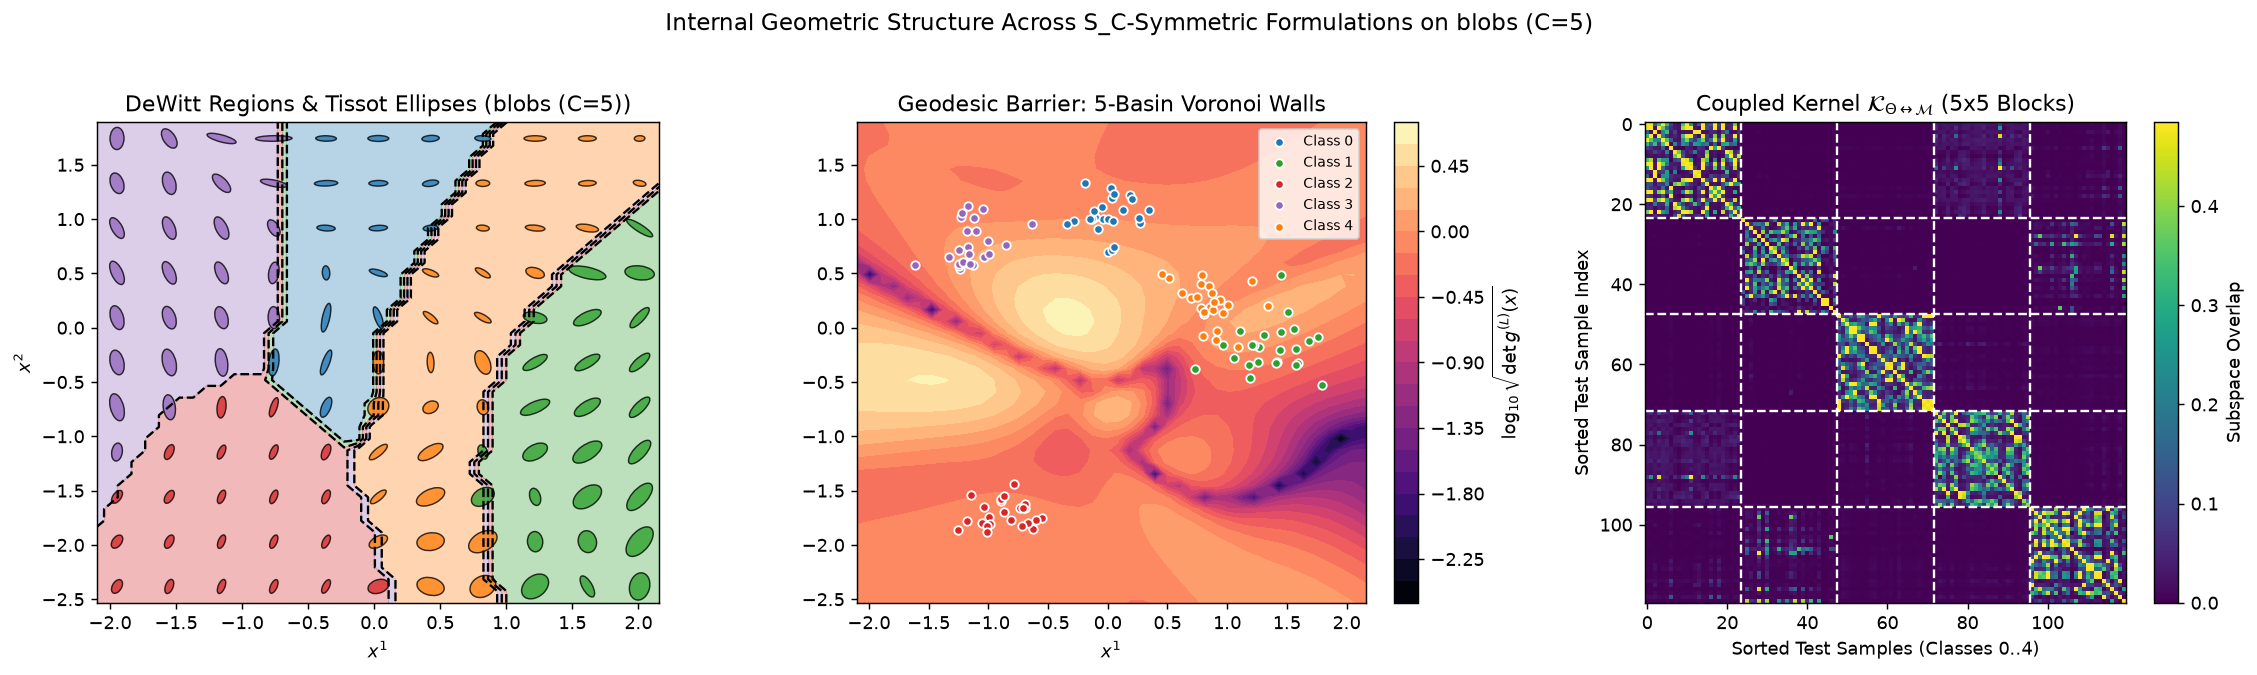

In [5]:
if X_cfg_tr.shape[1] == 2:
    res_vis = res_cfg
    X_v_tr, y_v_tr, X_v_te, y_v_te = X_cfg_tr, y_cfg_tr, X_cfg_te, y_cfg_te
    xx_v, yy_v, grid_v = xx_cfg, yy_cfg, grid_cfg
    C_vis = C_CFG
    vis_tag = f"{DATASET_NAME} (C={C_CFG})"
else:
    res_vis = res_tri
    X_v_tr, y_v_tr, X_v_te, y_v_te = X_tri_tr, y_tri_tr, X_tri_te, y_tri_te
    xx_v, yy_v, grid_v = xx_tri, yy_tri, grid_tri
    C_vis = 3
    vis_tag = "3-Class Triple-Junction"

mdl_dw_single = res_vis["New: DeWitt Simplex (Coupled NGD)"][2]
mdl_dw_fib = res_vis["New: DeWitt Fibered (Sym^+_2)^C"][2]
mdl_bar_vis = res_vis["New: Geodesic Barrier (Endpoint)"][2]
mdl_sub_vis = res_vis["New: Coupled Subspace Ortho"][2]
_, pisq_vis = build_dewitt_simplex_prototypes(C_vis, tau=0.75)

cmap_vis = ListedColormap([CLASS_COLORS[c % len(CLASS_COLORS)] for c in range(C_vis)])
cls_lvls = np.arange(-0.5, C_vis + 0.5, 1.0)
bnd_lvls = np.arange(0.5, C_vis - 0.5, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.0))

# Panel 0: Learned Symmetric Voronoi Regions & Tissot Metric Ellipses
_, _, coarse_v = make_evaluation_grid(X_v_tr, n_grid=11, padding=0.25)
with torch.no_grad():
    if C_vis <= 4:
        g_dw_bg = compute_layer_pullback_metric(mdl_dw_single, grid_v, layer_idx=mdl_dw_single.num_layers, metric_mode="graph")
        pred_dw_bg = dewitt_simplex_predict(g_dw_bg, pisq_vis).numpy().reshape(xx_v.shape)
        pred_c = dewitt_simplex_predict(
            compute_layer_pullback_metric(mdl_dw_single, coarse_v, layer_idx=mdl_dw_single.num_layers, metric_mode="graph"),
            pisq_vis,
        ).numpy()
    else:
        pred_dw_bg = fibered_dewitt_simplex_predict(mdl_dw_fib, grid_v, n_classes=C_vis).numpy().reshape(xx_v.shape)
        pred_c = fibered_dewitt_simplex_predict(mdl_dw_fib, coarse_v, n_classes=C_vis).numpy()

    g_dw_c = compute_layer_pullback_metric(mdl_dw_single, coarse_v, layer_idx=mdl_dw_single.num_layers, metric_mode="graph")
    evals_c, evecs_c, _ = compute_metric_spectrum(g_dw_c)
    s_c = np.sqrt(evals_c.numpy())
    norm_s = 0.25 / (np.percentile(s_c[:, 0], 90) + 1e-8)

axes[0].contourf(xx_v, yy_v, pred_dw_bg, levels=cls_lvls, cmap=cmap_vis, alpha=0.32)
axes[0].contour(xx_v, yy_v, pred_dw_bg, levels=bnd_lvls, colors="k", linewidths=1.3, linestyles="--")
pts_c = coarse_v.numpy()
ev_np = evecs_c.numpy()
for i in range(len(pts_c)):
    v1 = ev_np[i, :, 0]
    ang = np.degrees(np.arctan2(v1[1], v1[0]))
    c_id = int(pred_c[i])
    ell = Ellipse(pts_c[i], width=max(s_c[i, 0] * norm_s, 0.03), height=max(s_c[i, 1] * norm_s, 0.03), angle=ang, facecolor=CLASS_COLORS[c_id % len(CLASS_COLORS)], edgecolor="k", alpha=0.78, lw=0.8)
    axes[0].add_patch(ell)
axes[0].set_title(f"DeWitt Regions & Tissot Ellipses ({vis_tag})")
axes[0].set_xlabel("$x^1$")
axes[0].set_ylabel("$x^2$")

# Panel 1: Geodesic Barrier Multi-Basin Volume Ridges
with torch.no_grad():
    g_bar_grid = compute_layer_pullback_metric(mdl_bar_vis, grid_v, layer_idx=mdl_bar_vis.num_layers, metric_mode="euclidean", eps=1e-7)
    log10_vol_bar = (0.5 * torch.log10(torch.clamp(torch.linalg.det(g_bar_grid), min=1e-10))).numpy().reshape(xx_v.shape)

im1 = axes[1].contourf(xx_v, yy_v, log10_vol_bar, levels=22, cmap="magma")
for c in range(C_vis):
    mc = y_v_te == c
    axes[1].scatter(X_v_te[mc, 0], X_v_te[mc, 1], c=CLASS_COLORS[c % len(CLASS_COLORS)], edgecolors="w", s=22, label=f"Class {c}")
axes[1].set_title(f"Geodesic Barrier: {C_vis}-Basin Voronoi Walls")
axes[1].set_xlabel("$x^1$")
axes[1].legend(fontsize=7.6, loc="best")
plt.colorbar(im1, ax=axes[1], fraction=0.046, label=r"$\log_{10}\sqrt{\det g^{(L)}(x)}$")

# Panel 2: Coupled Parameter-Data Grassmannian Kernel Matrix on Sorted Test Set
sort_idx = torch.argsort(y_v_te)
X_te_sorted = X_v_te[sort_idx]
y_te_sorted = y_v_te[sort_idx]
W_te_s, _ = compute_coupled_subspace_factors(mdl_sub_vis, X_te_sorted, use_fd=True)
with torch.no_grad():
    cross_s = torch.einsum("nap,mbp->nmab", W_te_s.detach(), W_te_s.detach())
    K_sorted = (cross_s * cross_s).sum(dim=(-2, -1)).numpy()

im2 = axes[2].imshow(K_sorted, cmap="viridis", vmin=0.0, vmax=max(float(np.percentile(K_sorted, 98)), 0.1))
cum_cnt = 0
for c in range(C_vis - 1):
    cum_cnt += int((y_te_sorted == c).sum().item())
    axes[2].axhline(cum_cnt - 0.5, color="w", ls="--", lw=1.3)
    axes[2].axvline(cum_cnt - 0.5, color="w", ls="--", lw=1.3)
axes[2].set_title(rf"Coupled Kernel $\mathcal{{K}}_{{\Theta \leftrightarrow \mathcal{{M}}}}$ ({C_vis}x{C_vis} Blocks)")
axes[2].set_xlabel(f"Sorted Test Samples (Classes 0..{C_vis - 1})")
axes[2].set_ylabel("Sorted Test Sample Index")
plt.colorbar(im2, ax=axes[2], fraction=0.046, label="Subspace Overlap")

plt.suptitle(f"Internal Geometric Structure Across S_C-Symmetric Formulations on {vis_tag}", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

## 5. Scaling Compute Time & Memory Consumption: (1) Input Dimension $d_0$ and (2) Number of Classes $C$

### What These Two Experiments Do
We now stress-test how per-step compute latency (`ms / SGD step`) and CPU tensor memory (`MB / SGD step` via `torch.profiler`) scale along two independent axes, holding `torch.optim.SGD` constant across every curve:

1. **Experiment 5.1 — Scaling vs. Input Dimension $d_0 \in \{2, 4, 8, 16, 32, 64, 128\}$** (at fixed $C = 3$ classes, $N = 96$, MLP `[d_0, 16, 16, ...]`). Compares:
   - **`SGD + Cross-Entropy (1N)`** (1st-order coordinate baseline).
   - **`Prev Volume Band (Exact jacrev, 2nd)`** (symbolic $d_0 \times d_0$ metric autodiff).
   - **`New DeWitt Simplex — Full Coord FD ((d_0+1)N)`** (perturbs all $d_0$ axes before taking the $2 \times 2$ leading metric block).
   - **`New DeWitt Simplex — 2-Probe Plane Sketch (3N)`** (evaluates a $2 \times 2$ orthonormal tangent-plane metric $I_2 + g_{\mathrm{sub}}$ in strictly `3N` forward evaluations regardless of $d_0$).
   - **`New Geodesic Barrier — Full Coord FD ((d_0+1)N)`** (forms the full $d_0 \times d_0$ metric to contract $\Delta x_{ij} \in \mathbb{R}^{d_0}$).
   - **`New Coupled Subspace Ortho — 2-Probe Plane Sketch (2nd-θ)`** (uses `3N` spatial sketching, isolating how growing parameter count $P(d_0) = 16 d_0 + 322$ drives $O(P^3 + N P)$ parameter-Jacobian cost).

2. **Experiment 5.2 — Scaling vs. Number of Classes $C \in \{2, 3, 4, 8, 16, 32, 64\}$** (at fixed $d_0 = 2$, $N = 192$). Compares:
   - **`SGD + Cross-Entropy (d_L = C)`** (output layer grows linearly with $C$).
   - **`Prev 1D Volume Band (3-pt FD, d_L = 2)`** ($O(1)$ in $C$, though bands crowd onto $\mathbb{R}$).
   - **`New DeWitt Simplex — Single Sym^+_2 (3-pt FD, d_L = 2)`** (single $2 \times 2$ metric compared against $C$ prototypes in $O(N C)$ closed-form scalar ops).
   - **`New DeWitt Simplex — Exact Equidistant Fibered (Sym^+_2)^C (3-pt FD, d_L = 2C)`** (`fibered_dewitt_simplex_loss`: assigns each class its own 2D geometric fiber so all $\binom{C}{2}$ class pairs remain **strictly equidistant** for *any* $C \ge 2$ while evaluating distances in $O(N C)$ ops).
   - **`New Geodesic Barrier (Endpoint k-NN, 3-pt FD, d_L = 2)`** (pulls $k_{\mathrm{same}}$ same-class and pushes $k_{\mathrm{diff}}$ nearest cross-class neighbors).
   - **`New Coupled Subspace Ortho (FD, 2nd-θ, d_L = 2)`** (fixed parameter count $P$ and $(N \times N)$ overlap matrix independent of $C$).

### How to Interpret the Two Scaling Tables & $2 \times 2$ Log–Log Figure
- **Top Row (Experiment 5.1 — Input Dimension $d_0 = 2 \to 128$)**:
  - **Left (`Latency vs. d_0`) & Right (`Memory vs. d_0`)**: Coordinate-wise methods (`Exact jacrev`, `Full Coord FD`) climb steeply as $O(d_0)$–$O(d_0^2)$, and `Coupled Subspace Ortho` climbs steepest due to $P(d_0) \times P(d_0)$ parameter-metric eigendecomposition and `jacfwd` tangents. By contrast, **`DeWitt Simplex (2-Probe Plane Sketch, 3N)`** (solid green) stays **completely flat ($O(1)$ in $d_0$)**, tracking parallel to `SGD + Cross-Entropy`!
- **Bottom Row (Experiment 5.2 — Number of Classes $C = 2 \to 64$)**:
  - **Left (`Latency vs. C`) & Right (`Memory vs. C`)**: `Single Sym^+_2 DeWitt Simplex`, `Geodesic Barrier`, `1D Volume Band`, and `Coupled Subspace Ortho` are **invariant ($O(1)$) in $C$** from `2` to `64` classes because their network architecture (`d_L = 2`) does not depend on $C$.
  - **`Exact Equidistant Fibered (Sym^+_2)^C`** (teal triangles) scales gently and linearly $O(C)$ in its final `d_{L-1} -> 2C` output projection, staying under a few milliseconds and a few megabytes per step even at **`C = 64` classes** while guaranteeing zero crowding and exact $S_{64}$ symmetry!

=== Experiment 5.1: Step Latency (ms) / Memory (MB) vs. Input Dimension d_0 (C = 3, N = 96) ===
 d_0 |        SGD+CE |     Prev Exact2 |   DeWitt CoordFD |   DeWitt 2-Probe |   Barrier CoordFD |   Coupled Subsp.
--------------------------------------------------------------------------------------------------------------------
   2 |  0.86/0.19 |    4.29/  1.49 |     3.44/  1.32 |     3.58/  1.32 |      2.18/  1.25 |    57.24/ 659.4
   4 |  0.84/0.19 |    4.26/  1.62 |     2.91/  1.85 |     3.56/  1.33 |      3.00/  3.05 |    62.43/ 720.8
   8 |  0.91/0.19 |    2.90/  2.06 |     3.78/  3.04 |     3.33/  1.34 |      5.70/  9.20 |    63.56/ 844.7
  16 |  0.68/0.19 |    2.58/  3.64 |     3.37/  6.13 |     2.42/  1.37 |      4.49/ 31.79 |   105.57/1096.8
  32 |  0.68/0.20 |    4.18/  9.63 |     5.29/ 15.14 |     2.89/  1.44 |      8.96/118.06 |   176.25/1618.2
  64 |  0.76/0.21 |    2.75/ 32.89 |     4.93/ 44.49 |     2.22/  1.56 |     20.77/454.94 |   373.55/2730.1
 128 |  0.80/0.22 |    

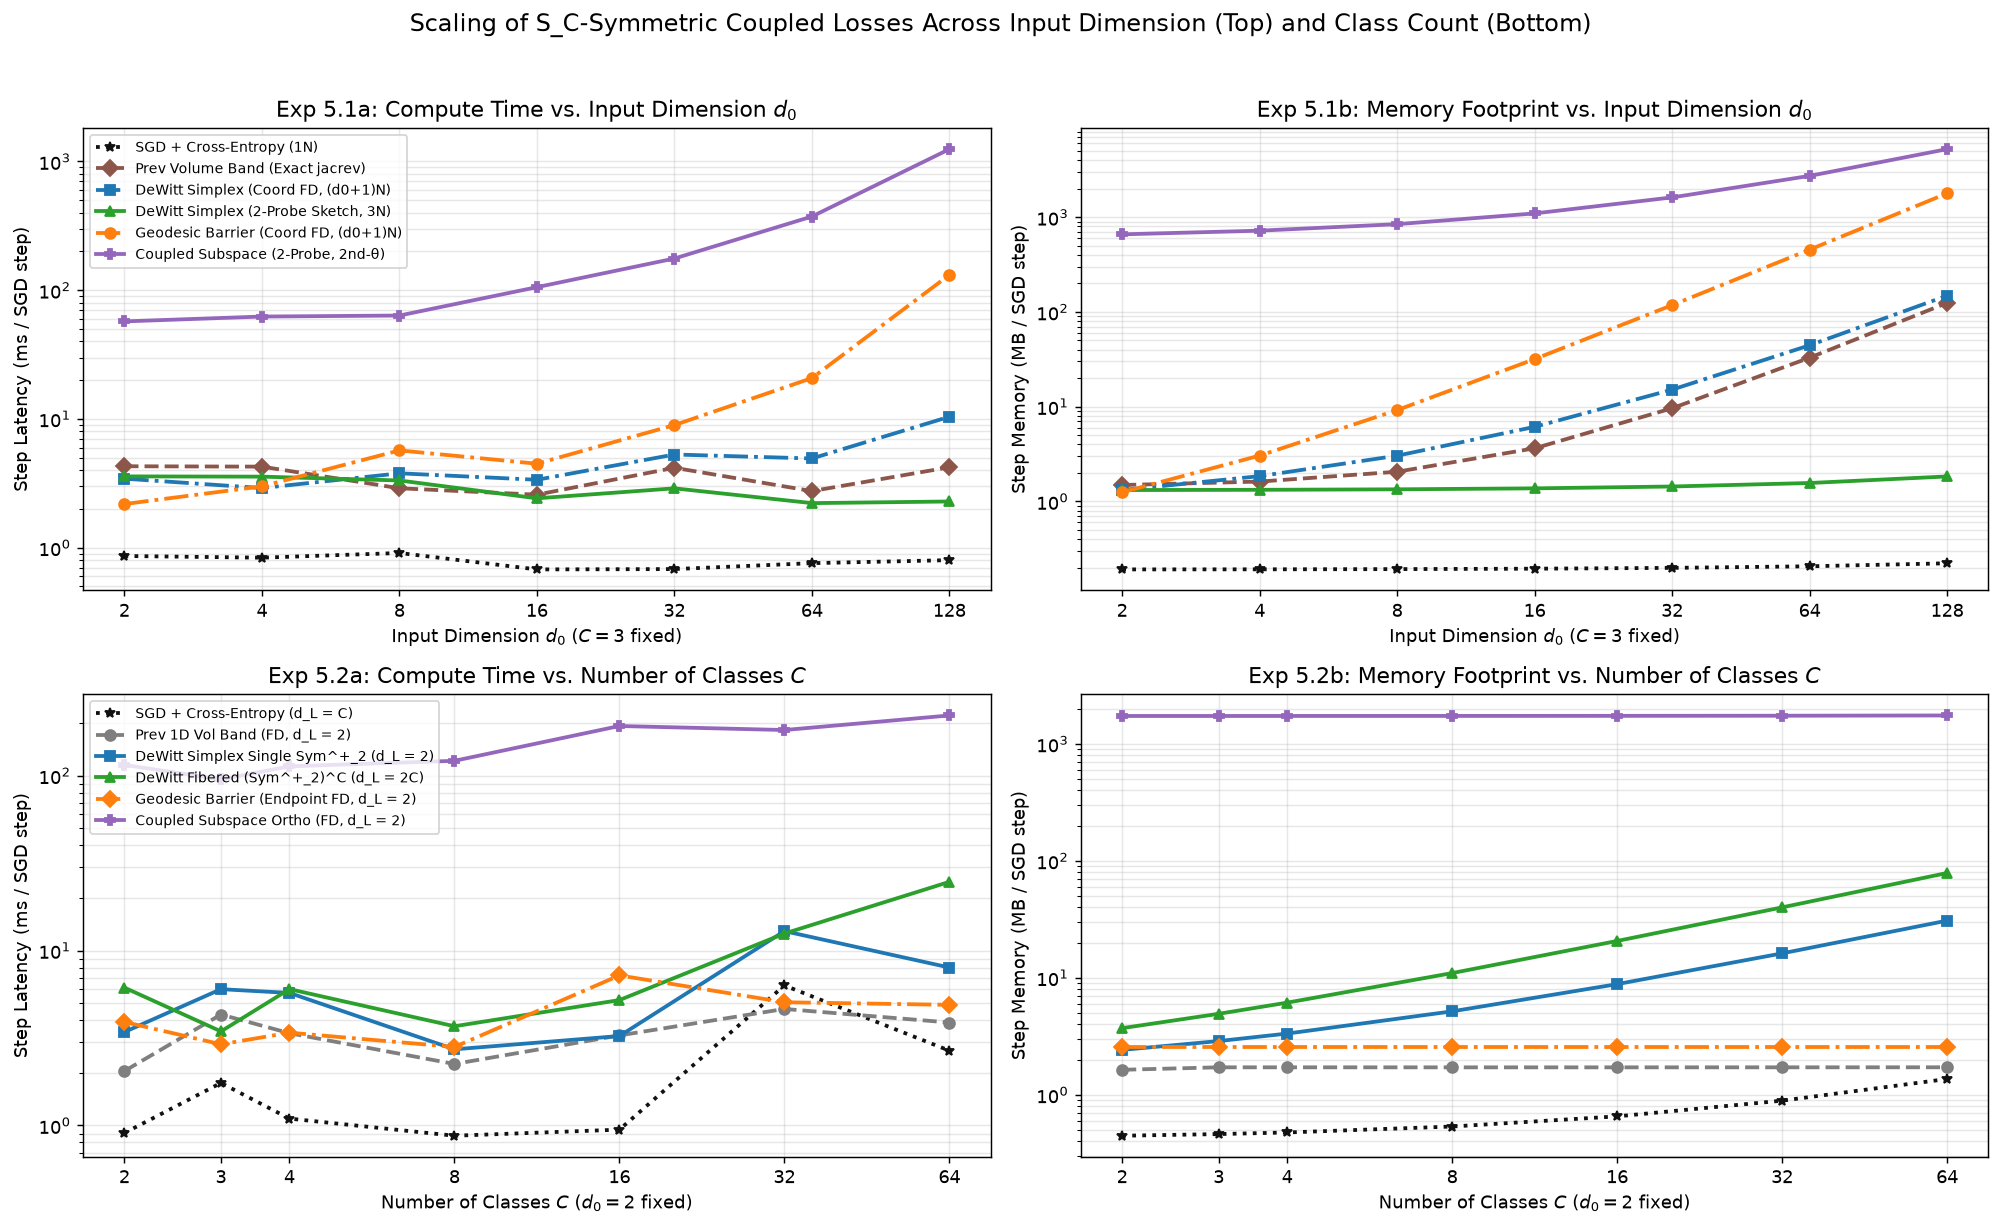

In [6]:
# =============================================================================
# Experiment 5.1: Compute & Memory Scaling vs. Ambient Input Dimension d_0
# =============================================================================
dims_sweep = [2, 4, 8, 16, 32, 64, 128]
N_d = 96
_, p_isq_3 = build_dewitt_simplex_prototypes(3, tau=0.75)
rng_d = torch.Generator().manual_seed(101)

dim_methods = {
    "SGD + Cross-Entropy (1N)": {"ms": [], "mb": [], "col": "#111111", "ls": ":", "mk": "*"},
    "Prev Volume Band (Exact jacrev)": {"ms": [], "mb": [], "col": "#8c564b", "ls": "--", "mk": "D"},
    "DeWitt Simplex (Coord FD, (d0+1)N)": {"ms": [], "mb": [], "col": "#1f77b4", "ls": "-.", "mk": "s"},
    "DeWitt Simplex (2-Probe Sketch, 3N)": {"ms": [], "mb": [], "col": "#2ca02c", "ls": "-", "mk": "^"},
    "Geodesic Barrier (Coord FD, (d0+1)N)": {"ms": [], "mb": [], "col": "#ff7f0e", "ls": "-.", "mk": "o"},
    "Coupled Subspace (2-Probe, 2nd-θ)": {"ms": [], "mb": [], "col": "#9467bd", "ls": "-", "mk": "P"},
}

for d0 in dims_sweep:
    X_d = torch.randn(N_d, d0, dtype=torch.float64)
    y_d = torch.arange(N_d) % 3
    s_sd, d_sd, s_dd, d_dd = build_metric_barrier_pairs(X_d, y_d, k_same=6, k_diff=8)

    net_ce_d = MoonsMLP(layer_dims=(d0, 16, 16, 3), activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    net_g_d = MoonsMLP(layer_dims=(d0, 16, 16, 2), activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    eye2_d = torch.eye(2, dtype=torch.float64).unsqueeze(0)

    ms, mb, _ = profile_training_step(lambda: ce_fn(net_ce_d(X_d), y_d), net_ce_d, n_repeats=12)
    dim_methods["SGD + Cross-Entropy (1N)"]["ms"].append(ms)
    dim_methods["SGD + Cross-Entropy (1N)"]["mb"].append(mb)

    def loss_prev_exact_d():
        g = compute_layer_pullback_metric(net_g_d, X_d, layer_idx=net_g_d.num_layers, metric_mode="euclidean", eps=1e-6, params=dict(net_g_d.named_parameters()))
        tr_lv = torch.log(torch.clamp(torch.diagonal(g, dim1=-2, dim2=-1).mean(-1), min=1e-8))
        return torch.nn.functional.softplus(0.5 - (2.0 * (y_d % 2).to(torch.float64) - 1.0) * tr_lv).mean()

    ms, mb, _ = profile_training_step(loss_prev_exact_d, net_g_d, n_repeats=8)
    dim_methods["Prev Volume Band (Exact jacrev)"]["ms"].append(ms)
    dim_methods["Prev Volume Band (Exact jacrev)"]["mb"].append(mb)

    def loss_dw_coord_fd():
        g_full = compute_fd_pullback_metric(net_g_d, X_d, metric_mode="graph")
        return dewitt_simplex_loss(g_full[:, :2, :2], y_d, p_isq_3)[0]

    ms, mb, _ = profile_training_step(loss_dw_coord_fd, net_g_d, n_repeats=8)
    dim_methods["DeWitt Simplex (Coord FD, (d0+1)N)"]["ms"].append(ms)
    dim_methods["DeWitt Simplex (Coord FD, (d0+1)N)"]["mb"].append(mb)

    def loss_dw_sketch_2p():
        _, g_sub = compute_sketched_pullback_metric(net_g_d, X_d, n_probes=2, metric_mode="graph", generator=rng_d, return_ambient=False)
        return dewitt_simplex_loss(eye2_d + g_sub, y_d, p_isq_3)[0]

    ms, mb, _ = profile_training_step(loss_dw_sketch_2p, net_g_d, n_repeats=12)
    dim_methods["DeWitt Simplex (2-Probe Sketch, 3N)"]["ms"].append(ms)
    dim_methods["DeWitt Simplex (2-Probe Sketch, 3N)"]["mb"].append(mb)

    def loss_bar_coord_fd():
        g_full = compute_fd_pullback_metric(net_g_d, X_d, metric_mode="euclidean")
        # Trace-stabilized barrier in d_0 dimensions (avoiding det underflow when rank(J) <= 2 < d_0)
        dx_s = X_d[d_sd] - X_d[s_sd]
        e_s = torch.einsum("pi,pij,pj->p", dx_s, 0.5 * (g_full[s_sd] + g_full[d_sd]), dx_s).mean()
        dx_df = X_d[d_dd] - X_d[s_dd]
        d_df = torch.sqrt(torch.clamp(torch.einsum("pi,pij,pj->p", dx_df, 0.5 * (g_full[s_dd] + g_full[d_dd]), dx_df), min=1e-10))
        return e_s + torch.nn.functional.softplus(1.5 - d_df, beta=4.0).mean()

    ms, mb, _ = profile_training_step(loss_bar_coord_fd, net_g_d, n_repeats=8)
    dim_methods["Geodesic Barrier (Coord FD, (d0+1)N)"]["ms"].append(ms)
    dim_methods["Geodesic Barrier (Coord FD, (d0+1)N)"]["mb"].append(mb)

    ms, mb, _ = profile_training_step(
        lambda: coupled_subspace_orthogonality_loss(net_g_d, X_d[:64], y_d[:64], use_fd=True, plane_sketch=True)[0],
        net_g_d,
        n_repeats=4,
    )
    dim_methods["Coupled Subspace (2-Probe, 2nd-θ)"]["ms"].append(ms)
    dim_methods["Coupled Subspace (2-Probe, 2nd-θ)"]["mb"].append(mb)

print("=== Experiment 5.1: Step Latency (ms) / Memory (MB) vs. Input Dimension d_0 (C = 3, N = 96) ===")
print(f"{'d_0':>4} | {'SGD+CE':>13} | {'Prev Exact2':>15} | {'DeWitt CoordFD':>16} | {'DeWitt 2-Probe':>16} | {'Barrier CoordFD':>17} | {'Coupled Subsp.':>16}")
print("-" * 116)
for i, d0 in enumerate(dims_sweep):
    print(
        f"{d0:4d} | "
        f"{dim_methods['SGD + Cross-Entropy (1N)']['ms'][i]:5.2f}/{dim_methods['SGD + Cross-Entropy (1N)']['mb'][i]:4.2f} | "
        f"{dim_methods['Prev Volume Band (Exact jacrev)']['ms'][i]:7.2f}/{dim_methods['Prev Volume Band (Exact jacrev)']['mb'][i]:6.2f} | "
        f"{dim_methods['DeWitt Simplex (Coord FD, (d0+1)N)']['ms'][i]:8.2f}/{dim_methods['DeWitt Simplex (Coord FD, (d0+1)N)']['mb'][i]:6.2f} | "
        f"{dim_methods['DeWitt Simplex (2-Probe Sketch, 3N)']['ms'][i]:8.2f}/{dim_methods['DeWitt Simplex (2-Probe Sketch, 3N)']['mb'][i]:6.2f} | "
        f"{dim_methods['Geodesic Barrier (Coord FD, (d0+1)N)']['ms'][i]:9.2f}/{dim_methods['Geodesic Barrier (Coord FD, (d0+1)N)']['mb'][i]:6.2f} | "
        f"{dim_methods['Coupled Subspace (2-Probe, 2nd-θ)']['ms'][i]:8.2f}/{dim_methods['Coupled Subspace (2-Probe, 2nd-θ)']['mb'][i]:6.1f}"
    )

# =============================================================================
# Experiment 5.2: Compute & Memory Scaling vs. Number of Classes C
# =============================================================================
classes_sweep = [2, 3, 4, 8, 16, 32, 64]
N_c = 192  # >= 3 samples per class even at C = 64
X_cls = torch.randn(N_c, 2, dtype=torch.float64)
hidden_mid = LAYER_DIMS[1:-1] if len(LAYER_DIMS) > 2 else [16, 16]

cls_methods = {
    "SGD + Cross-Entropy (d_L = C)": {"ms": [], "mb": [], "col": "#111111", "ls": ":", "mk": "*"},
    "Prev 1D Vol Band (FD, d_L = 2)": {"ms": [], "mb": [], "col": "#7f7f7f", "ls": "--", "mk": "o"},
    "DeWitt Simplex Single Sym^+_2 (d_L = 2)": {"ms": [], "mb": [], "col": "#1f77b4", "ls": "-", "mk": "s"},
    "DeWitt Fibered (Sym^+_2)^C (d_L = 2C)": {"ms": [], "mb": [], "col": "#2ca02c", "ls": "-", "mk": "^"},
    "Geodesic Barrier (Endpoint FD, d_L = 2)": {"ms": [], "mb": [], "col": "#ff7f0e", "ls": "-.", "mk": "D"},
    "Coupled Subspace Ortho (FD, d_L = 2)": {"ms": [], "mb": [], "col": "#9467bd", "ls": "-", "mk": "P"},
}

for c_cnt in classes_sweep:
    y_c = torch.arange(N_c) % c_cnt
    _, p_isq_c = build_dewitt_simplex_prototypes(c_cnt, tau=0.75)
    s_sc, d_sc, s_dc, d_dc = build_metric_barrier_pairs(X_cls, y_c, k_same=2, k_diff=8)

    net_ce_c = MoonsMLP(layer_dims=[2, *hidden_mid, c_cnt], activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    net_2d_c = MoonsMLP(layer_dims=[2, *hidden_mid, 2], activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)
    net_fib_c = MoonsMLP(layer_dims=[2, *hidden_mid, 2 * c_cnt], activation=HIDDEN_ACTIVATION, output_activation=OUTPUT_ACTIVATION, seed=7)

    ms, mb, _ = profile_training_step(lambda: ce_fn(net_ce_c(X_cls), y_c), net_ce_c, n_repeats=15)
    cls_methods["SGD + Cross-Entropy (d_L = C)"]["ms"].append(ms)
    cls_methods["SGD + Cross-Entropy (d_L = C)"]["mb"].append(mb)

    ms, mb, _ = profile_training_step(
        lambda: volume_contrastive_loss(compute_fd_pullback_metric(net_2d_c, X_cls, metric_mode="euclidean"), y_c, margin=0.40, n_classes=c_cnt)[0],
        net_2d_c,
        n_repeats=15,
    )
    cls_methods["Prev 1D Vol Band (FD, d_L = 2)"]["ms"].append(ms)
    cls_methods["Prev 1D Vol Band (FD, d_L = 2)"]["mb"].append(mb)

    ms, mb, _ = profile_training_step(
        lambda: dewitt_simplex_loss(compute_fd_pullback_metric(net_2d_c, X_cls, metric_mode="graph"), y_c, p_isq_c)[0],
        net_2d_c,
        n_repeats=15,
    )
    cls_methods["DeWitt Simplex Single Sym^+_2 (d_L = 2)"]["ms"].append(ms)
    cls_methods["DeWitt Simplex Single Sym^+_2 (d_L = 2)"]["mb"].append(mb)

    ms, mb, _ = profile_training_step(
        lambda: fibered_dewitt_simplex_loss(net_fib_c, X_cls, y_c, n_classes=c_cnt)[0],
        net_fib_c,
        n_repeats=15,
    )
    cls_methods["DeWitt Fibered (Sym^+_2)^C (d_L = 2C)"]["ms"].append(ms)
    cls_methods["DeWitt Fibered (Sym^+_2)^C (d_L = 2C)"]["mb"].append(mb)

    ms, mb, _ = profile_training_step(
        lambda: geodesic_barrier_loss(compute_fd_pullback_metric(net_2d_c, X_cls, metric_mode="euclidean"), X_cls, s_sc, d_sc, s_dc, d_dc)[0],
        net_2d_c,
        n_repeats=15,
    )
    cls_methods["Geodesic Barrier (Endpoint FD, d_L = 2)"]["ms"].append(ms)
    cls_methods["Geodesic Barrier (Endpoint FD, d_L = 2)"]["mb"].append(mb)

    ms, mb, _ = profile_training_step(
        lambda: coupled_subspace_orthogonality_loss(net_2d_c, X_cls[:96], y_c[:96], use_fd=True)[0],
        net_2d_c,
        n_repeats=5,
    )
    cls_methods["Coupled Subspace Ortho (FD, d_L = 2)"]["ms"].append(ms)
    cls_methods["Coupled Subspace Ortho (FD, d_L = 2)"]["mb"].append(mb)

print("\n=== Experiment 5.2: Step Latency (ms) / Memory (MB) vs. Number of Classes C (d_0 = 2, N = 192) ===")
print(f"{'C':>4} | {'SGD+CE (dL=C)':>14} | {'Prev 1D Band':>14} | {'DeWitt Sym^+_2':>16} | {'DeWitt (Sym^+_2)^C':>19} | {'Geod. Barrier':>15} | {'Coupled Subsp.':>16}")
print("-" * 118)
for i, c_cnt in enumerate(classes_sweep):
    print(
        f"{c_cnt:4d} | "
        f"{cls_methods['SGD + Cross-Entropy (d_L = C)']['ms'][i]:6.2f}/{cls_methods['SGD + Cross-Entropy (d_L = C)']['mb'][i]:5.2f} | "
        f"{cls_methods['Prev 1D Vol Band (FD, d_L = 2)']['ms'][i]:6.2f}/{cls_methods['Prev 1D Vol Band (FD, d_L = 2)']['mb'][i]:5.2f} | "
        f"{cls_methods['DeWitt Simplex Single Sym^+_2 (d_L = 2)']['ms'][i]:8.2f}/{cls_methods['DeWitt Simplex Single Sym^+_2 (d_L = 2)']['mb'][i]:5.2f} | "
        f"{cls_methods['DeWitt Fibered (Sym^+_2)^C (d_L = 2C)']['ms'][i]:10.2f}/{cls_methods['DeWitt Fibered (Sym^+_2)^C (d_L = 2C)']['mb'][i]:6.2f} | "
        f"{cls_methods['Geodesic Barrier (Endpoint FD, d_L = 2)']['ms'][i]:7.2f}/{cls_methods['Geodesic Barrier (Endpoint FD, d_L = 2)']['mb'][i]:5.2f} | "
        f"{cls_methods['Coupled Subspace Ortho (FD, d_L = 2)']['ms'][i]:8.2f}/{cls_methods['Coupled Subspace Ortho (FD, d_L = 2)']['mb'][i]:5.1f}"
    )

fig, axes = plt.subplots(2, 2, figsize=(15.5, 9.2))

for name, d in dim_methods.items():
    axes[0, 0].plot(dims_sweep, d["ms"], marker=d["mk"], color=d["col"], ls=d["ls"], lw=2.1, label=name)
    axes[0, 1].plot(dims_sweep, d["mb"], marker=d["mk"], color=d["col"], ls=d["ls"], lw=2.1, label=name)

for col_i, (ylbl, ttl) in enumerate([
    ("Step Latency (ms / SGD step)", r"Exp 5.1a: Compute Time vs. Input Dimension $d_0$"),
    ("Step Memory (MB / SGD step)", r"Exp 5.1b: Memory Footprint vs. Input Dimension $d_0$"),
]):
    axes[0, col_i].set_xscale("log", base=2)
    axes[0, col_i].set_yscale("log")
    axes[0, col_i].set_xticks(dims_sweep)
    axes[0, col_i].set_xticklabels([str(v) for v in dims_sweep])
    axes[0, col_i].set_xlabel(r"Input Dimension $d_0$ ($C = 3$ fixed)")
    axes[0, col_i].set_ylabel(ylbl)
    axes[0, col_i].set_title(ttl)
    axes[0, col_i].grid(alpha=0.3, which="both")
axes[0, 0].legend(fontsize=7.8, loc="upper left")

for name, d in cls_methods.items():
    axes[1, 0].plot(classes_sweep, d["ms"], marker=d["mk"], color=d["col"], ls=d["ls"], lw=2.1, label=name)
    axes[1, 1].plot(classes_sweep, d["mb"], marker=d["mk"], color=d["col"], ls=d["ls"], lw=2.1, label=name)

for col_i, (ylbl, ttl) in enumerate([
    ("Step Latency (ms / SGD step)", r"Exp 5.2a: Compute Time vs. Number of Classes $C$"),
    ("Step Memory (MB / SGD step)", r"Exp 5.2b: Memory Footprint vs. Number of Classes $C$"),
]):
    axes[1, col_i].set_xscale("log", base=2)
    axes[1, col_i].set_yscale("log")
    axes[1, col_i].set_xticks(classes_sweep)
    axes[1, col_i].set_xticklabels([str(v) for v in classes_sweep])
    axes[1, col_i].set_xlabel(r"Number of Classes $C$ ($d_0 = 2$ fixed)")
    axes[1, col_i].set_ylabel(ylbl)
    axes[1, col_i].set_title(ttl)
    axes[1, col_i].grid(alpha=0.3, which="both")
axes[1, 0].legend(fontsize=7.8, loc="upper left")

plt.suptitle("Scaling of S_C-Symmetric Coupled Losses Across Input Dimension (Top) and Class Count (Bottom)", y=1.02, fontsize=13.5)
plt.tight_layout()
plt.show()